In [94]:

# Download NASA OSDR datasets directly into Google Colab

!pip -q install boto3

import boto3
from botocore import UNSIGNED
from botocore.config import Config
import os

# Connect to NASA's public AWS bucket
s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

os.makedirs("/content/nasa_data", exist_ok=True)

files = {
    "CBC.csv": "OSD-569/version-4/Complete_Blood_Count/LSDS-7_Complete_Blood_Count_CBC_TRANSFORMED.csv",

    "CMP.csv": "OSD-575/version-3/Comprehensive_Metabolic_Panel/LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv",

    "Immune.csv": "OSD-575/version-3/Multiplex/LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv",

    "Cardiovascular.csv": "OSD-575/version-3/Multiplex/LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv"
}

for filename, key in files.items():
    destination = f"/content/nasa_data/{filename}"

    try:
        s3.download_file("nasa-osdr", key, destination)
        print("Downloaded:", filename)
    except Exception as e:
        print("Download failed:", filename, e)

print("\nDownloaded files:")
print(os.listdir("/content/nasa_data"))


Downloaded: CBC.csv
Downloaded: CMP.csv
Downloaded: Immune.csv
Downloaded: Cardiovascular.csv

Downloaded files:
['Cardiovascular.csv', 'CMP.csv', 'CBC.csv', 'Immune.csv']


In [95]:

import pandas as pd
import numpy as np
import os

data_folder = "/content/nasa_data"

cbc = pd.read_csv(f"{data_folder}/CBC.csv")
cmp = pd.read_csv(f"{data_folder}/CMP.csv")
immune = pd.read_csv(f"{data_folder}/Immune.csv")
cardio = pd.read_csv(f"{data_folder}/Cardiovascular.csv")

print("CBC:", cbc.shape)
print("CMP:", cmp.shape)
print("Immune:", immune.shape)
print("Cardiovascular:", cardio.shape)


CBC: (28, 61)
CMP: (28, 58)
Immune: (28, 143)
Cardiovascular: (28, 19)


In [96]:

display(cbc.head())


,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,...,platelet_count_range_max_thousand_per_microliter,rdw_value_percent,rdw_range_min_percent,rdw_range_max_percent,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,...,400,12.6,11,15,4.69,4.2,5.8,7.0,3.8,10.8
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,...,400,12.6,11,15,4.85,4.2,5.8,5.5,3.8,10.8
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,...,400,13.0,11,15,4.58,4.2,5.8,5.4,3.8,10.8
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,...,400,12.5,11,15,4.84,4.2,5.8,5.0,3.8,10.8
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,...,400,12.8,11,15,4.66,4.2,5.8,4.9,3.8,10.8


In [97]:

print("CBC columns:")
print(cbc.columns.tolist())

print("\nCMP columns:")
print(cmp.columns.tolist())

print("\nImmune columns:")
print(immune.columns.tolist())

print("\nCardiovascular columns:")
print(cardio.columns.tolist())


CBC columns:
['Sample Name', 'absolute_basophils_value_cells_per_microliter', 'absolute_basophils_range_min_cells_per_microliter', 'absolute_basophils_range_max_cells_per_microliter', 'absolute_eosinophils_value_cells_per_microliter', 'absolute_eosinophils_range_min_cells_per_microliter', 'absolute_eosinophils_range_max_cells_per_microliter', 'absolute_lymphocytes_value_cells_per_microliter', 'absolute_lymphocytes_range_min_cells_per_microliter', 'absolute_lymphocytes_range_max_cells_per_microliter', 'absolute_monocytes_value_cells_per_microliter', 'absolute_monocytes_range_min_cells_per_microliter', 'absolute_monocytes_range_max_cells_per_microliter', 'absolute_neutrophils_value_cells_per_microliter', 'absolute_neutrophils_range_min_cells_per_microliter', 'absolute_neutrophils_range_max_cells_per_microliter', 'basophils_value_percent', 'basophils_range_min_percent', 'basophils_range_max_percent', 'eosinophils_value_percent', 'eosinophils_range_min_percent', 'eosinophils_range_max_perc

In [98]:

cbc.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 61 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Sample Name                                               28 non-null     object 
 1   absolute_basophils_value_cells_per_microliter             28 non-null     int64  
 2   absolute_basophils_range_min_cells_per_microliter         28 non-null     int64  
 3   absolute_basophils_range_max_cells_per_microliter         28 non-null     int64  
 4   absolute_eosinophils_value_cells_per_microliter           28 non-null     int64  
 5   absolute_eosinophils_range_min_cells_per_microliter       28 non-null     int64  
 6   absolute_eosinophils_range_max_cells_per_microliter       28 non-null     int64  
 7   absolute_lymphocytes_value_cells_per_microliter           28 non-null     int64  
 8   absolute_lymphocytes_r

In [99]:

display(cbc.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sample Name,28,28,C001_whole-blood_L-3_cbc,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
absolute_basophils_value_cells_per_microliter,28.0,NaN,NaN,NaN,58.928571,25.191016,19.0,45.0,50.5,71.75,125.0
absolute_basophils_range_min_cells_per_microliter,28.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
absolute_basophils_range_max_cells_per_microliter,28.0,NaN,NaN,NaN,200.0,0.0,200.0,200.0,200.0,200.0,200.0
absolute_eosinophils_value_cells_per_microliter,28.0,NaN,NaN,NaN,211.214286,103.151581,88.0,157.75,190.5,258.25,614.0
...,...,...,...,...,...,...,...,...,...,...,...
red_blood_cell_count_range_min_million_per_microliter,28.0,NaN,NaN,NaN,4.042857,0.198939,3.8,3.8,4.2,4.2,4.2
red_blood_cell_count_range_max_million_per_microliter,28.0,NaN,NaN,NaN,5.525,0.348143,5.1,5.1,5.8,5.8,5.8
white_blood_cell_count_value_thousand_per_microliter,28.0,NaN,NaN,NaN,6.992857,1.635696,4.9,5.475,6.9,7.95,10.6
white_blood_cell_count_range_min_thousand_per_microliter,28.0,NaN,NaN,NaN,3.8,0.0,3.8,3.8,3.8,3.8,3.8


In [100]:

for name, df in {
    "CBC": cbc,
    "CMP": cmp,
    "Immune": immune,
    "Cardiovascular": cardio
}.items():

    print(f"\n{name} missing values:")
    print(df.isnull().sum())



CBC missing values:
Sample Name                                                 0
absolute_basophils_value_cells_per_microliter               0
absolute_basophils_range_min_cells_per_microliter           0
absolute_basophils_range_max_cells_per_microliter           0
absolute_eosinophils_value_cells_per_microliter             0
                                                           ..
red_blood_cell_count_range_min_million_per_microliter       0
red_blood_cell_count_range_max_million_per_microliter       0
white_blood_cell_count_value_thousand_per_microliter        0
white_blood_cell_count_range_min_thousand_per_microliter    0
white_blood_cell_count_range_max_thousand_per_microliter    0
Length: 61, dtype: int64

CMP missing values:
Sample Name                                                                          0
albumin_value_gram_per_deciliter                                                     0
albumin_range_min_gram_per_deciliter                                         

In [101]:

for name, df in {
    "CBC": cbc,
    "CMP": cmp,
    "Immune": immune,
    "Cardiovascular": cardio
}.items():

    print(name, "duplicate rows:", df.duplicated().sum())


CBC duplicate rows: 0
CMP duplicate rows: 0
Immune duplicate rows: 0
Cardiovascular duplicate rows: 0


In [102]:

cbc = cbc.drop_duplicates().copy()
cmp = cmp.drop_duplicates().copy()
immune = immune.drop_duplicates().copy()
cardio = cardio.drop_duplicates().copy()

print("Duplicate rows removed.")


Duplicate rows removed.


In [103]:

!pip -q install matplotlib seaborn scikit-learn scipy


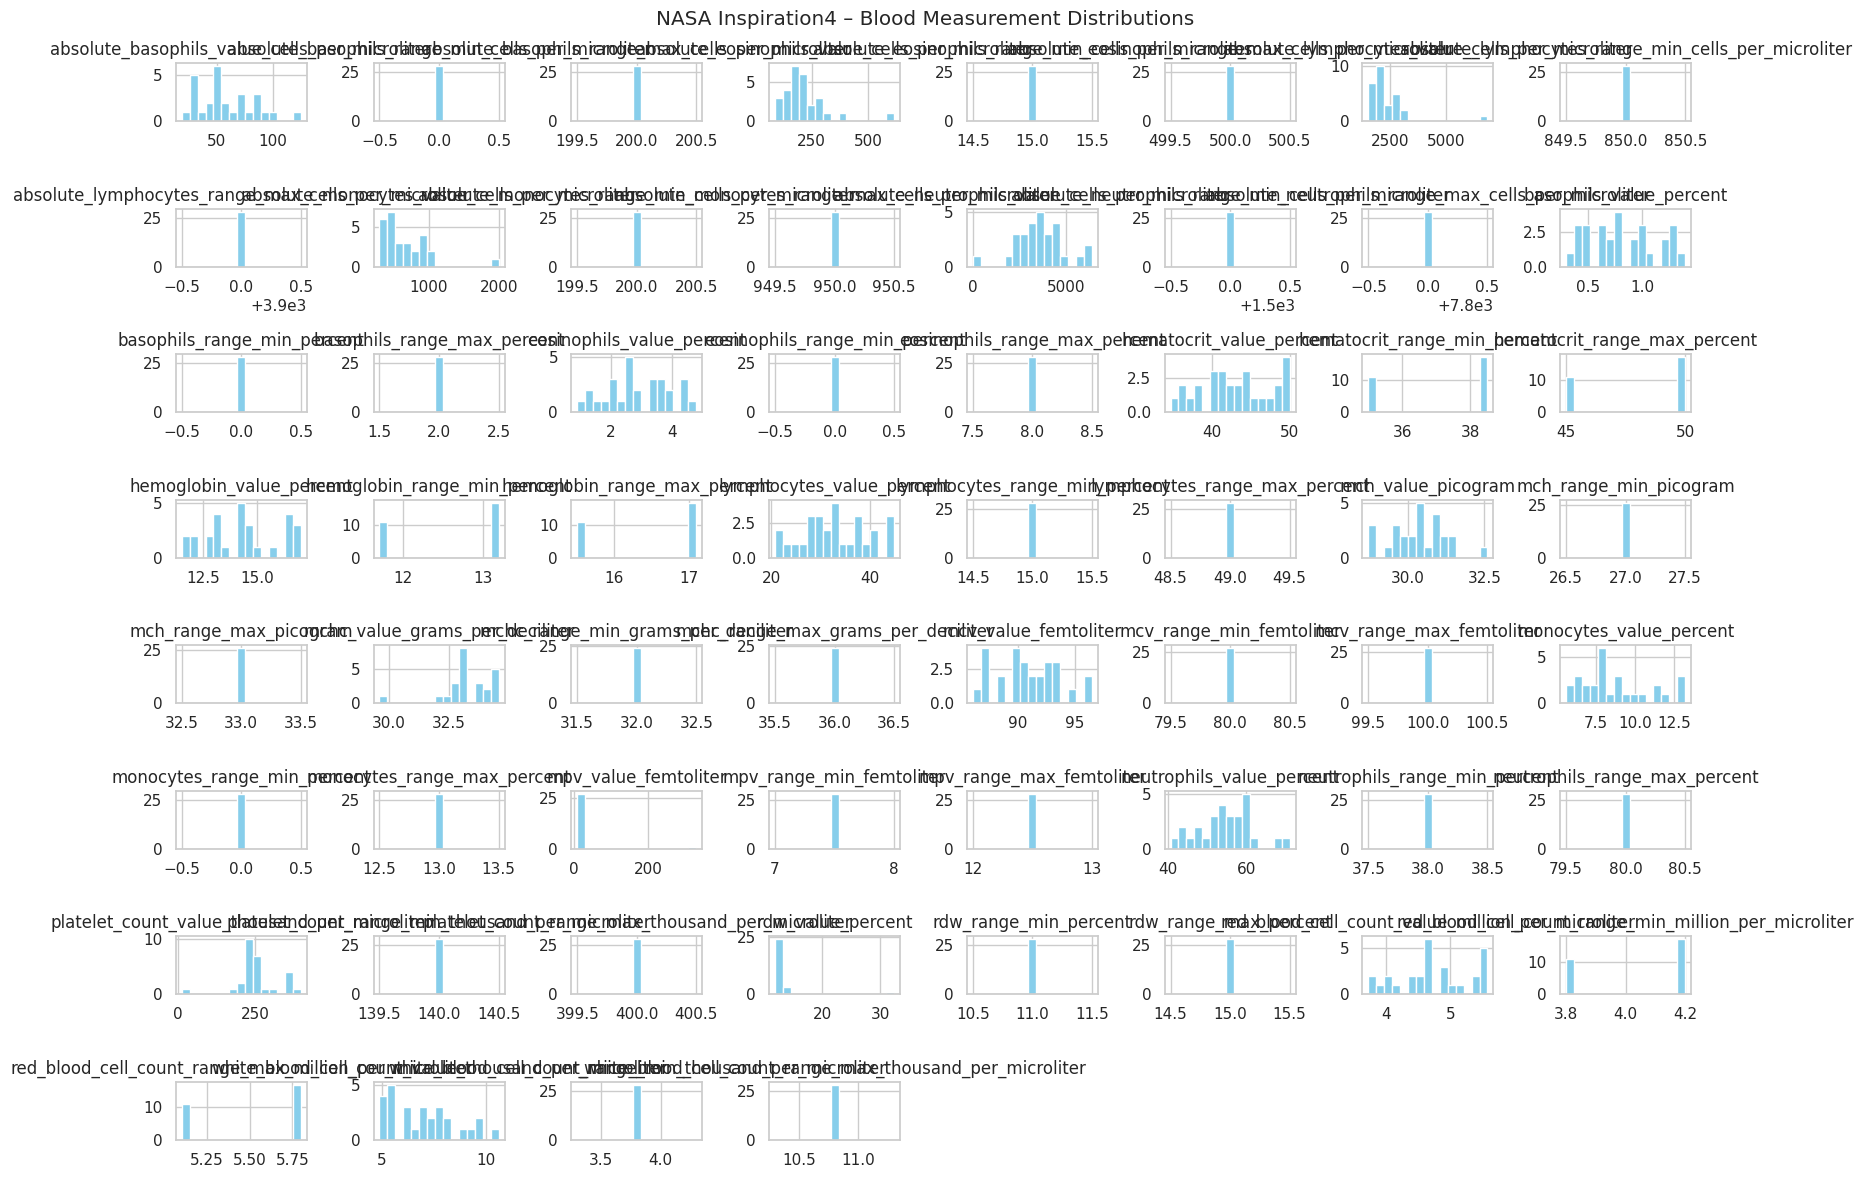

In [104]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

numeric_cbc = cbc.select_dtypes(include=np.number)

numeric_cbc.hist(
    figsize=(16, 12),
    bins=15,
    color="skyblue"
)

plt.suptitle("NASA Inspiration4 – Blood Measurement Distributions")
plt.tight_layout()
plt.show()


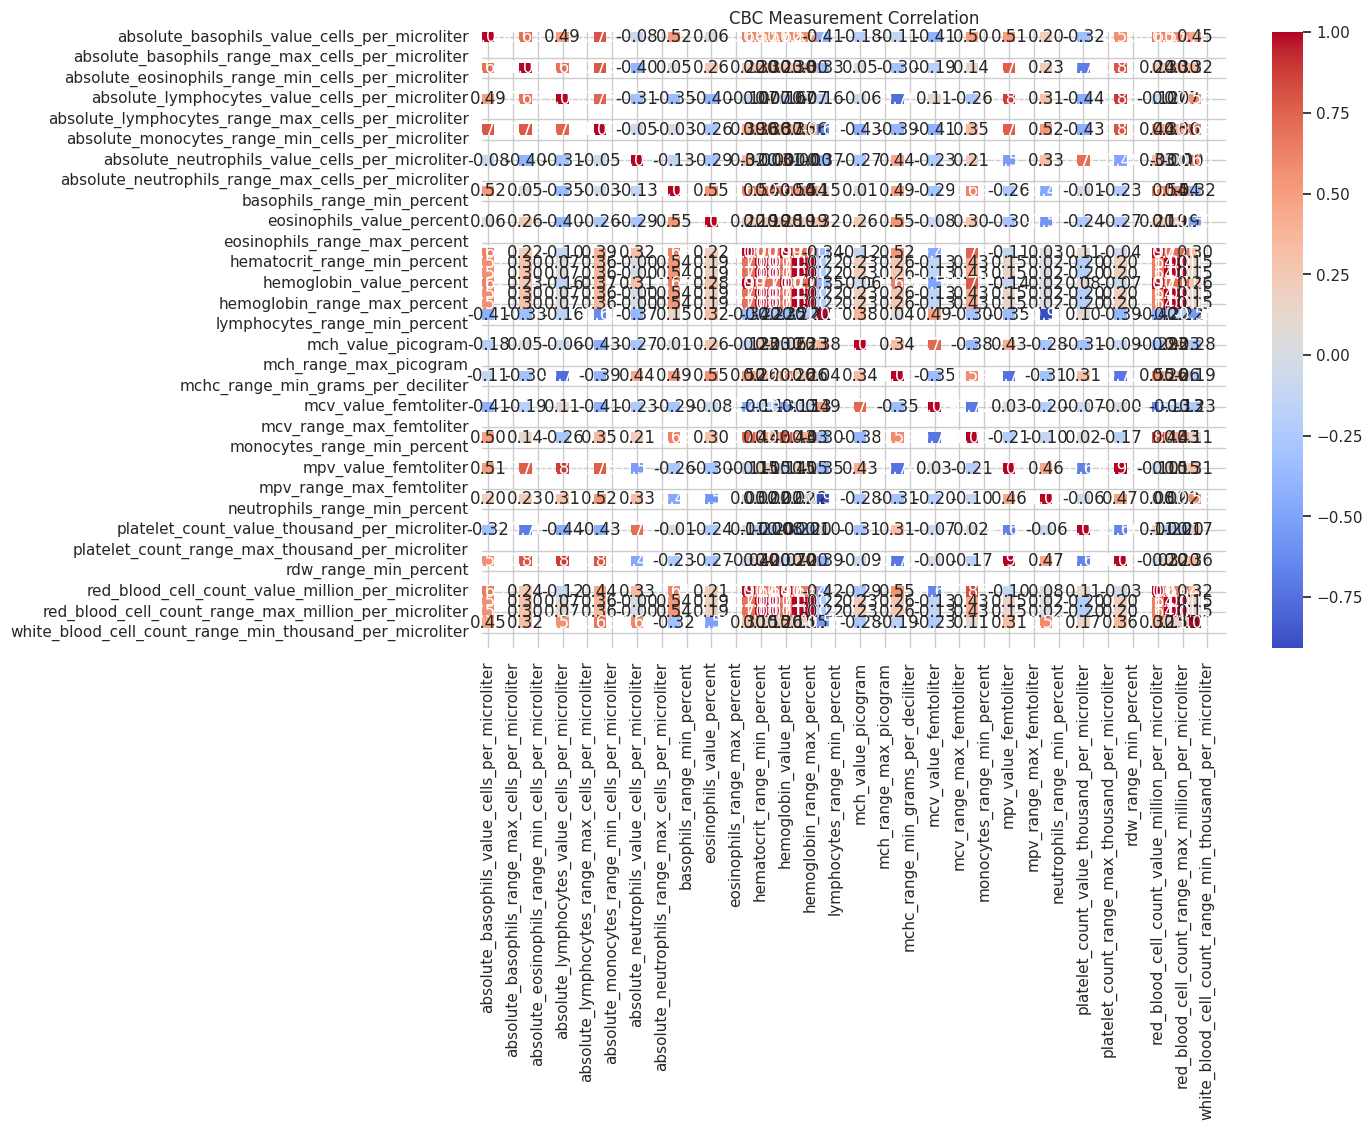

In [105]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_cbc.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("CBC Measurement Correlation")
plt.show()


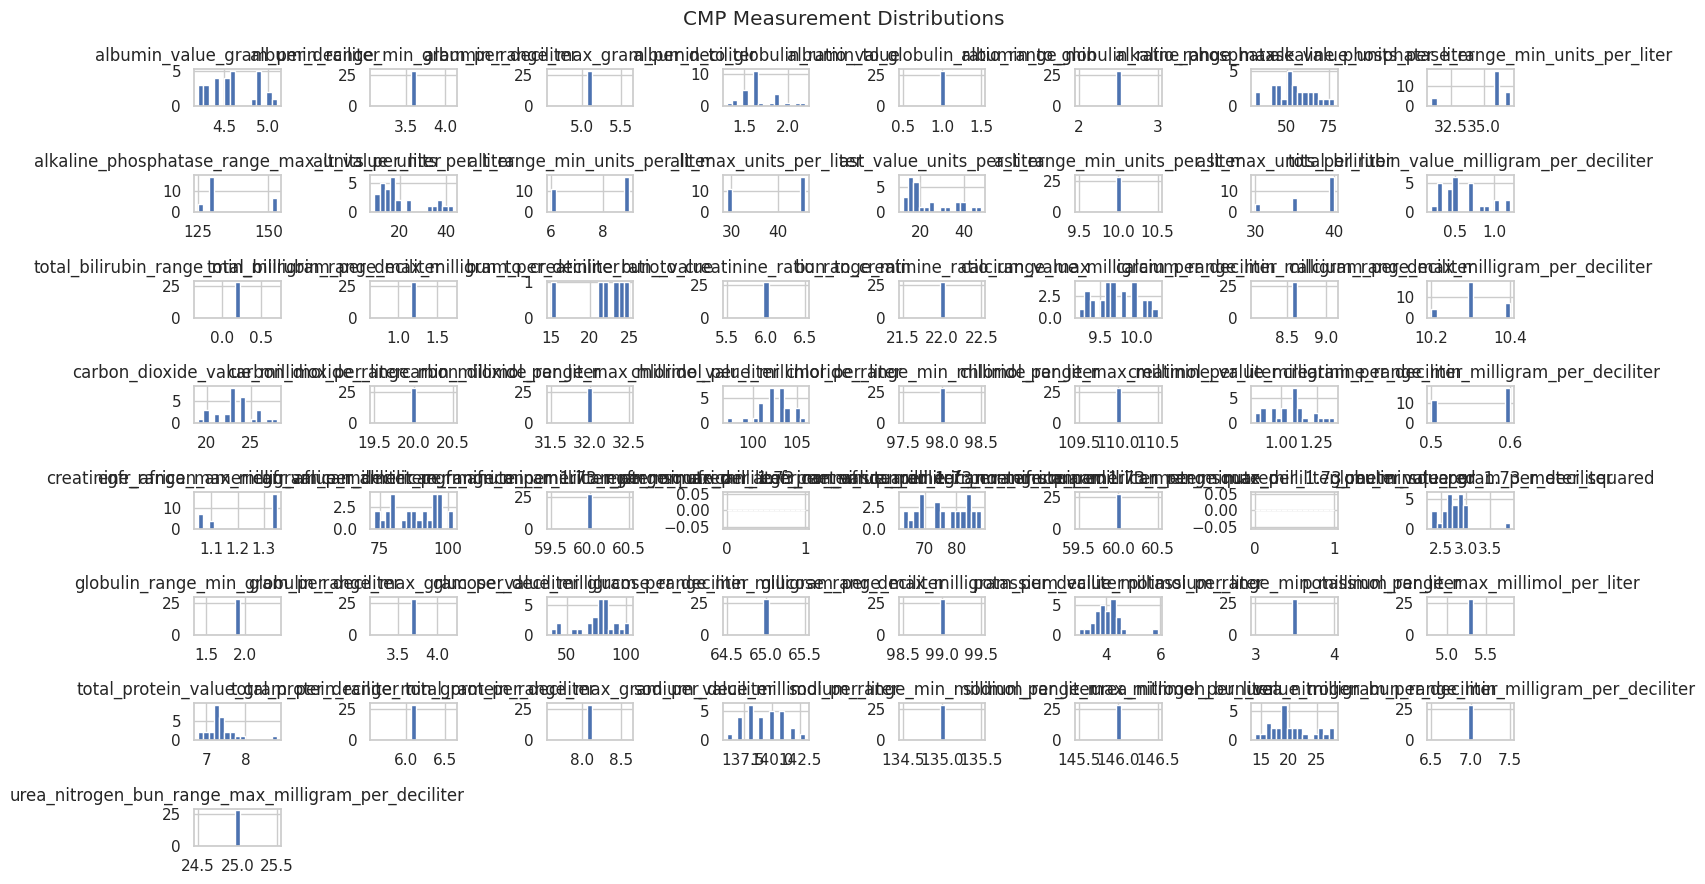

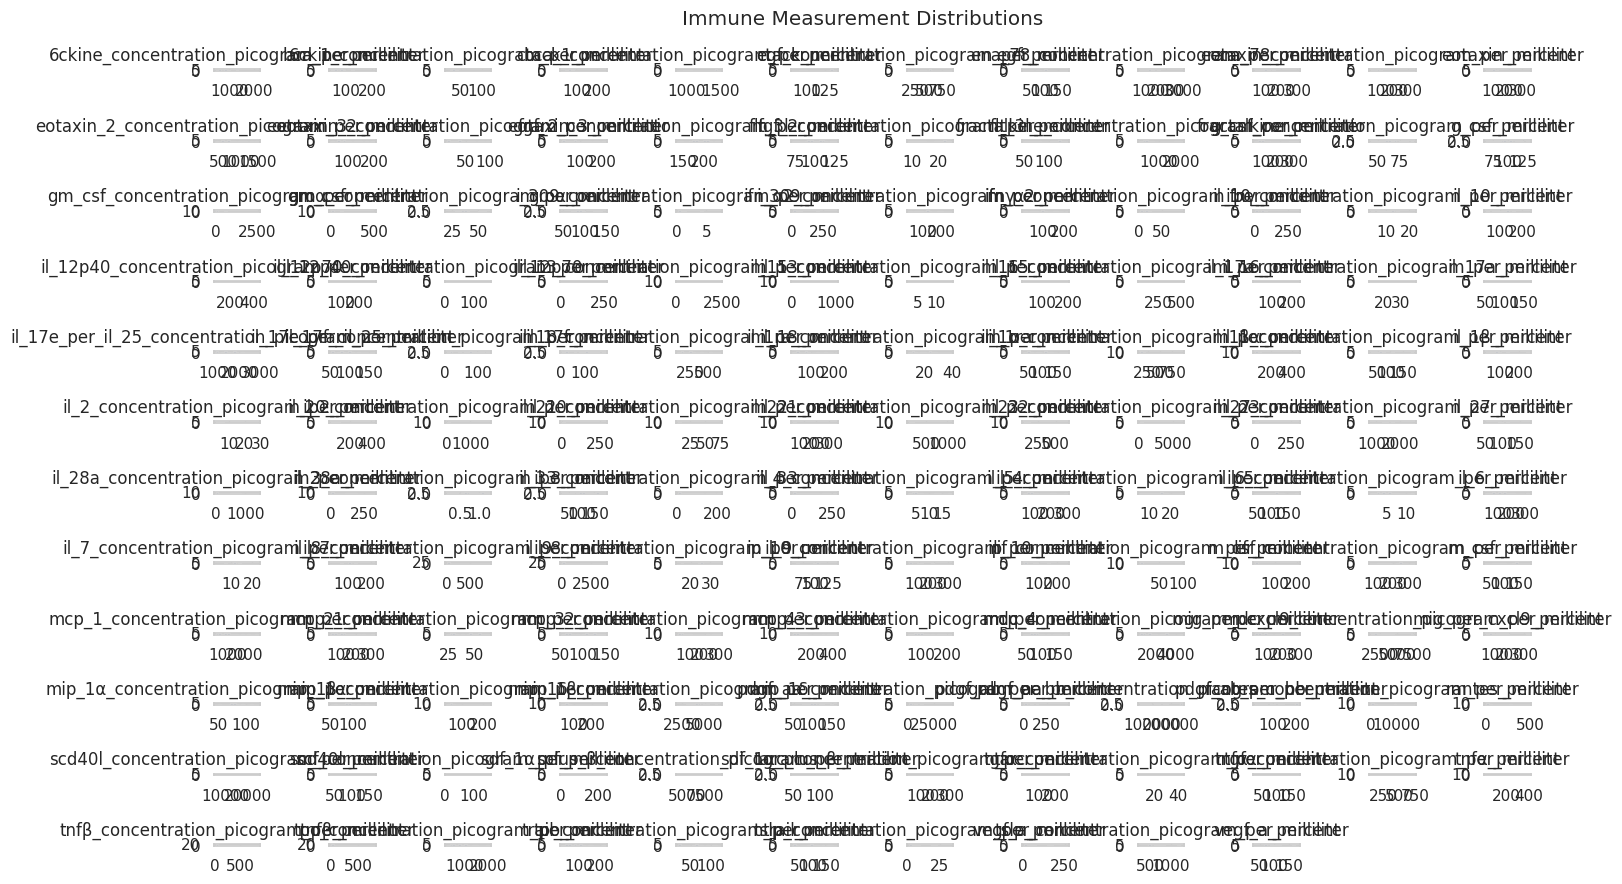

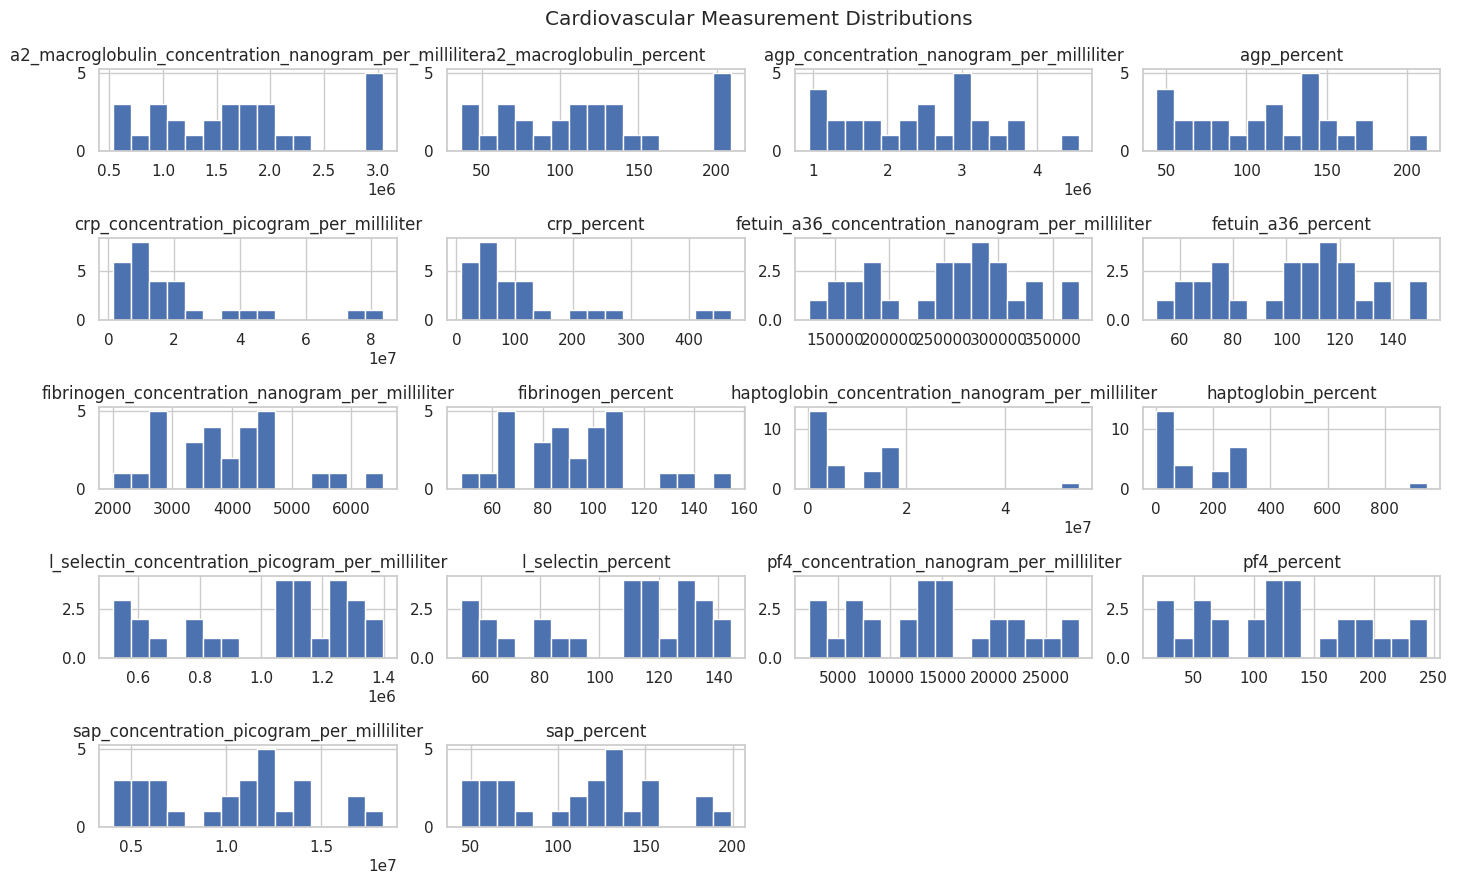

In [106]:

datasets = {
    "CMP": cmp,
    "Immune": immune,
    "Cardiovascular": cardio
}

for name, df in datasets.items():

    numeric = df.select_dtypes(include=np.number)

    if numeric.shape[1] == 0:
        print(name, "has no numeric columns")
        continue

    numeric.hist(figsize=(14, 9), bins=15)
    plt.suptitle(f"{name} Measurement Distributions")
    plt.tight_layout()
    plt.show()


In [107]:

import os
from google.colab import files
import zipfile

# Create output folder
output_folder = "/content/processed_data"
os.makedirs(output_folder, exist_ok=True)

# Export all datasets
cbc.to_csv(f"{output_folder}/CBC_cleaned.csv", index=False)
cmp.to_csv(f"{output_folder}/CMP_cleaned.csv", index=False)
immune.to_csv(f"{output_folder}/Immune_cleaned.csv", index=False)
cardio.to_csv(f"{output_folder}/Cardiovascular_cleaned.csv", index=False)

# Create ZIP file
zip_path = "/content/processed_datasets.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for file in os.listdir(output_folder):
        zipf.write(
            os.path.join(output_folder, file),
            arcname=file
        )

print("All four datasets exported successfully!")

# Download all datasets together
files.download(zip_path)


All four datasets exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [108]:
import pandas as pd
import os

output_folder = "/content/processed_data"

datasets = {
    "CBC": "CBC_cleaned.csv",
    "CMP": "CMP_cleaned.csv",
    "Immune": "Immune_cleaned.csv",
    "Cardiovascular": "Cardiovascular_cleaned.csv"
}

loaded_data = {}

for name, filename in datasets.items():
    path = os.path.join(output_folder, filename)

    loaded_data[name] = pd.read_csv(path)

    print(f"\n{name}")
    print("Shape:", loaded_data[name].shape)
    print("Missing values:", loaded_data[name].isnull().sum().sum())
    print("Duplicate rows:", loaded_data[name].duplicated().sum())

print("\nAll exported datasets verified!")


CBC
Shape: (28, 61)
Missing values: 21
Duplicate rows: 0

CMP
Shape: (28, 58)
Missing values: 81
Duplicate rows: 0

Immune
Shape: (28, 143)
Missing values: 0
Duplicate rows: 0

Cardiovascular
Shape: (28, 19)
Missing values: 0
Duplicate rows: 0

All exported datasets verified!


In [109]:
# Extract sample names from all datasets

sample_sets = {
    name: set(df["Sample Name"])
    for name, df in loaded_data.items()
}

# Check sample counts
for name, samples in sample_sets.items():
    print(f"{name}: {len(samples)} unique samples")

# Compare sample names
reference_samples = sample_sets["CBC"]

for name, samples in sample_sets.items():
    print(f"\n{name} matches CBC:",
          samples == reference_samples)

# Find missing or extra samples
for name, samples in sample_sets.items():
    if name != "CBC":
        print(f"\n{name} missing samples:",
              reference_samples - samples)

        print(f"{name} extra samples:",
              samples - reference_samples)

CBC: 28 unique samples
CMP: 28 unique samples
Immune: 28 unique samples
Cardiovascular: 28 unique samples

CBC matches CBC: True

CMP matches CBC: False

Immune matches CBC: False

Cardiovascular matches CBC: False

CMP missing samples: {'C001_whole-blood_R+1_cbc', 'C003_whole-blood_L-92_cbc', 'C003_whole-blood_R+194_cbc', 'C002_whole-blood_L-92_cbc', 'C002_whole-blood_L-3_cbc', 'C004_whole-blood_R+194_cbc', 'C003_whole-blood_R+45_cbc', 'C001_whole-blood_L-3_cbc', 'C002_whole-blood_R+82_cbc', 'C001_whole-blood_R+45_cbc', 'C002_whole-blood_R+194_cbc', 'C003_whole-blood_R+82_cbc', 'C002_whole-blood_R+45_cbc', 'C002_whole-blood_L-44_cbc', 'C003_whole-blood_R+1_cbc', 'C004_whole-blood_R+82_cbc', 'C004_whole-blood_L-3_cbc', 'C001_whole-blood_L-44_cbc', 'C001_whole-blood_R+82_cbc', 'C003_whole-blood_L-3_cbc', 'C004_whole-blood_L-44_cbc', 'C003_whole-blood_L-44_cbc', 'C004_whole-blood_L-92_cbc', 'C004_whole-blood_R+45_cbc', 'C002_whole-blood_R+1_cbc', 'C001_whole-blood_R+194_cbc', 'C004_whole

In [110]:
# Create standardized sample identifiers

def standardize_sample_name(name):
    return (
        name.replace("_whole-blood_", "_")
            .replace("_serum_", "_")
            .replace("_cbc", "")
    )

for df in [cbc, cmp, immune, cardio]:
    df["Sample_ID"] = df["Sample Name"].apply(
        standardize_sample_name
    )

# Check matching samples
print("CBC matches CMP:",
      set(cbc["Sample_ID"]) == set(cmp["Sample_ID"]))

print("CBC matches Immune:",
      set(cbc["Sample_ID"]) == set(immune["Sample_ID"]))

print("CBC matches Cardiovascular:",
      set(cbc["Sample_ID"]) == set(cardio["Sample_ID"]))

CBC matches CMP: True
CBC matches Immune: True
CBC matches Cardiovascular: True


In [111]:
# Merge all four datasets using standardized Sample_ID

merged_df = cbc.merge(
    cmp.drop(columns=["Sample Name"]),
    on="Sample_ID",
    how="inner"
)

merged_df = merged_df.merge(
    immune.drop(columns=["Sample Name"]),
    on="Sample_ID",
    how="inner"
)

merged_df = merged_df.merge(
    cardio.drop(columns=["Sample Name"]),
    on="Sample_ID",
    how="inner"
)

print("Merged dataset shape:", merged_df.shape)
print("Unique samples:", merged_df["Sample_ID"].nunique())

display(merged_df.head())

Merged dataset shape: (28, 279)
Unique samples: 28


,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,...,fibrinogen_concentration_nanogram_per_milliliter,fibrinogen_percent,haptoglobin_concentration_nanogram_per_milliliter,haptoglobin_percent,l_selectin_concentration_picogram_per_milliliter,l_selectin_percent,pf4_concentration_nanogram_per_milliliter,pf4_percent,sap_concentration_picogram_per_milliliter,sap_percent
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,...,2780.38,65.861344,1305900.00,22.434959,561452.93,57.944587,8602.35,74.659519,6057300,66.132482
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,...,5707.32,135.194386,122441.48,2.103507,675114.37,69.674983,3903.78,33.880781,5428000,59.261901
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,...,3208.77,76.009001,1049100.00,18.023214,515957.20,53.249214,6973.32,60.521220,4760000,51.968801
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,...,2604.70,61.699855,853104.40,14.656070,596429.89,61.554374,8143.69,70.678823,6183500,67.510311
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,...,4587.13,108.659445,55113000.00,946.824327,762532.23,78.696918,11371.31,98.691233,7739400,84.497339


In [112]:
# Check merged dataset quality

print("Dataset shape:", merged_df.shape)

print("\nMissing values:")
print("Total missing:", merged_df.isnull().sum().sum())

print("\nDuplicate rows:",
      merged_df.duplicated().sum())

print("\nDuplicate sample IDs:",
      merged_df["Sample_ID"].duplicated().sum())

print("\nData types:")
print(merged_df.dtypes.value_counts())

print("\nDataset information:")
merged_df.info()

Dataset shape: (28, 279)

Missing values:
Total missing: 102

Duplicate rows: 0

Duplicate sample IDs: 0

Data types:
float64    217
int64       60
object       2
Name: count, dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Columns: 279 entries, Sample Name to sap_percent
dtypes: float64(217), int64(60), object(2)
memory usage: 61.2+ KB


In [113]:
# Identify columns containing missing values

missing_summary = merged_df.isnull().sum()

missing_summary = missing_summary[
    missing_summary > 0
].sort_values(ascending=False)

print("Columns with missing values:")
display(missing_summary)

print("\nTotal affected columns:",
      len(missing_summary))

print("\nTotal missing values:",
      missing_summary.sum())

Columns with missing values:


,0
egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
bun_to_creatinine_ratio_value,22
mchc_range_min_grams_per_deciliter,4
mchc_range_max_grams_per_deciliter,4
mchc_value_grams_per_deciliter,4
mch_range_max_picogram,2
mch_range_min_picogram,2
mch_value_picogram,2
mcv_value_femtoliter,1



Total affected columns: 15

Total missing values: 102


In [114]:
# Show samples with missing values

missing_rows = merged_df[
    merged_df.isnull().any(axis=1)
]

print("Samples containing missing values:",
      len(missing_rows))

display(
    missing_rows[
        ["Sample Name"] +
        missing_summary.index.tolist()
    ]
)

Samples containing missing values: 28


,Sample Name,egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,bun_to_creatinine_ratio_value,mchc_range_min_grams_per_deciliter,mchc_range_max_grams_per_deciliter,mchc_value_grams_per_deciliter,mch_range_max_picogram,mch_range_min_picogram,mch_value_picogram,mcv_value_femtoliter,mcv_range_min_femtoliter,total_bilirubin_value_milligram_per_deciliter,mcv_range_max_femtoliter,bun_to_creatinine_ratio_range_max,bun_to_creatinine_ratio_range_min
0,C001_whole-blood_L-3_cbc,NaN,NaN,15.0,32.0,36.0,33.0,33.0,27.0,31.3,94.9,80.0,1.0,100.0,22.0,6.0
1,C001_whole-blood_L-44_cbc,NaN,NaN,NaN,32.0,36.0,33.0,33.0,27.0,30.7,93.0,80.0,0.9,100.0,22.0,6.0
2,C001_whole-blood_L-92_cbc,NaN,NaN,NaN,32.0,36.0,33.2,33.0,27.0,30.8,92.8,80.0,0.7,100.0,22.0,6.0
3,C001_whole-blood_R+1_cbc,NaN,NaN,NaN,32.0,36.0,33.7,33.0,27.0,30.4,90.1,80.0,1.2,100.0,22.0,6.0
4,C001_whole-blood_R+194_cbc,NaN,NaN,22.0,32.0,36.0,33.7,33.0,27.0,30.3,89.7,80.0,0.8,100.0,22.0,6.0
5,C001_whole-blood_R+45_cbc,NaN,NaN,NaN,32.0,36.0,33.0,33.0,27.0,30.9,93.5,80.0,NaN,100.0,22.0,6.0
6,C001_whole-blood_R+82_cbc,NaN,NaN,NaN,32.0,36.0,34.1,33.0,27.0,31.3,91.8,80.0,1.2,100.0,22.0,6.0
7,C002_whole-blood_L-3_cbc,NaN,NaN,NaN,NaN,NaN,NaN,33.0,27.0,30.9,96.5,80.0,0.3,100.0,22.0,6.0
8,C002_whole-blood_L-44_cbc,NaN,NaN,NaN,NaN,NaN,NaN,33.0,27.0,32.6,96.2,80.0,0.4,100.0,22.0,6.0
9,C002_whole-blood_L-92_cbc,NaN,NaN,NaN,NaN,NaN,NaN,33.0,27.0,30.3,93.6,80.0,0.5,100.0,22.0,6.0


In [115]:
# Make a copy of the merged dataset
final_df = merged_df.copy()

# Identify columns that are completely empty
empty_columns = final_df.columns[
    final_df.isnull().all()
].tolist()

print("Completely empty columns:", empty_columns)

# Remove only completely empty columns
final_df.drop(
    columns=empty_columns,
    inplace=True
)

# Verify the cleaned dataset
print("\nFinal dataset shape:", final_df.shape)

print("Remaining missing values:",
      final_df.isnull().sum().sum())

print("Duplicate rows:",
      final_df.duplicated().sum())

display(final_df.head())

Completely empty columns: ['egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared', 'egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared']

Final dataset shape: (28, 277)
Remaining missing values: 46
Duplicate rows: 0


,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,...,fibrinogen_concentration_nanogram_per_milliliter,fibrinogen_percent,haptoglobin_concentration_nanogram_per_milliliter,haptoglobin_percent,l_selectin_concentration_picogram_per_milliliter,l_selectin_percent,pf4_concentration_nanogram_per_milliliter,pf4_percent,sap_concentration_picogram_per_milliliter,sap_percent
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,...,2780.38,65.861344,1305900.00,22.434959,561452.93,57.944587,8602.35,74.659519,6057300,66.132482
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,...,5707.32,135.194386,122441.48,2.103507,675114.37,69.674983,3903.78,33.880781,5428000,59.261901
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,...,3208.77,76.009001,1049100.00,18.023214,515957.20,53.249214,6973.32,60.521220,4760000,51.968801
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,...,2604.70,61.699855,853104.40,14.656070,596429.89,61.554374,8143.69,70.678823,6183500,67.510311
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,...,4587.13,108.659445,55113000.00,946.824327,762532.23,78.696918,11371.31,98.691233,7739400,84.497339


In [116]:
# Analyze remaining missing values

remaining_missing = final_df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Remaining missing-value columns:")
display(remaining_missing)

print("\nTotal affected columns:",
      len(remaining_missing))

print("\nTotal missing values:",
      remaining_missing.sum())

print("\nMissing-value percentage:",
      round(
          final_df.isnull().sum().sum()
          / final_df.size * 100, 2
      ), "%")

Remaining missing-value columns:


,0
bun_to_creatinine_ratio_value,22
mchc_value_grams_per_deciliter,4
mchc_range_min_grams_per_deciliter,4
mchc_range_max_grams_per_deciliter,4
mch_value_picogram,2
mch_range_min_picogram,2
mch_range_max_picogram,2
mcv_range_min_femtoliter,1
mcv_value_femtoliter,1
mcv_range_max_femtoliter,1



Total affected columns: 13

Total missing values: 46

Missing-value percentage: 0.59 %


In [117]:
import os

# Create final output folder
final_folder = "/content/final_research_data"
os.makedirs(final_folder, exist_ok=True)

# Export final merged dataset
final_df.to_csv(
    f"{final_folder}/OSD569_Final_Merged_Dataset.csv",
    index=False
)

# Export missing-value report
remaining_missing.to_csv(
    f"{final_folder}/Missing_Values_Report.csv"
)

print("Final research dataset saved successfully!")
print("Dataset shape:", final_df.shape)
print("Total samples:", final_df.shape[0])
print("Total features:", final_df.shape[1])
print("Missing values:", final_df.isnull().sum().sum())

Final research dataset saved successfully!
Dataset shape: (28, 277)
Total samples: 28
Total features: 277
Missing values: 46


In [118]:
from google.colab import files

files.download(
    "/content/final_research_data/OSD569_Final_Merged_Dataset.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset shape: (28, 277)

First 5 rows:


,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,...,fibrinogen_concentration_nanogram_per_milliliter,fibrinogen_percent,haptoglobin_concentration_nanogram_per_milliliter,haptoglobin_percent,l_selectin_concentration_picogram_per_milliliter,l_selectin_percent,pf4_concentration_nanogram_per_milliliter,pf4_percent,sap_concentration_picogram_per_milliliter,sap_percent
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,...,2780.38,65.861344,1305900.00,22.434959,561452.93,57.944587,8602.35,74.659519,6057300,66.132482
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,...,5707.32,135.194386,122441.48,2.103507,675114.37,69.674983,3903.78,33.880781,5428000,59.261901
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,...,3208.77,76.009001,1049100.00,18.023214,515957.20,53.249214,6973.32,60.521220,4760000,51.968801
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,...,2604.70,61.699855,853104.40,14.656070,596429.89,61.554374,8143.69,70.678823,6183500,67.510311
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,...,4587.13,108.659445,55113000.00,946.824327,762532.23,78.696918,11371.31,98.691233,7739400,84.497339



Selected biomarkers:
['hemoglobin_value_percent', 'hematocrit_value_percent', 'white_blood_cell_count_value_thousand_per_microliter', 'platelet_count_value_thousand_per_microliter', 'glucose_value_milligram_per_deciliter', 'creatinine_value_milligram_per_deciliter', 'albumin_value_gram_per_deciliter', 'crp_concentration_picogram_per_milliliter']


,count,mean,std,min,25%,50%,75%,max
hemoglobin_value_percent,28.0,1.435000e+01,1.685779e+00,11.50,1.320000e+01,14.35,1.587500e+01,17.00
hematocrit_value_percent,28.0,4.301429e+01,4.399387e+00,34.70,4.062500e+01,42.95,4.645000e+01,50.00
white_blood_cell_count_value_thousand_per_microliter,28.0,6.992857e+00,1.635696e+00,4.90,5.475000e+00,6.90,7.950000e+00,10.60
platelet_count_value_thousand_per_microliter,28.0,2.539607e+02,7.065072e+01,12.90,2.287500e+02,242.00,2.637500e+02,396.00
glucose_value_milligram_per_deciliter,28.0,7.642857e+01,1.622624e+01,36.00,7.125000e+01,80.00,8.400000e+01,103.00
creatinine_value_milligram_per_deciliter,28.0,1.067500e+00,1.434657e-01,0.82,9.575000e-01,1.08,1.132500e+00,1.37
albumin_value_gram_per_deciliter,28.0,4.589286e+00,2.726268e-01,4.20,4.400000e+00,4.55,4.900000e+00,5.10
crp_concentration_picogram_per_milliliter,28.0,1.972549e+07,2.058135e+07,1289600.00,8.450850e+06,12323500.00,2.169825e+07,83617000.00


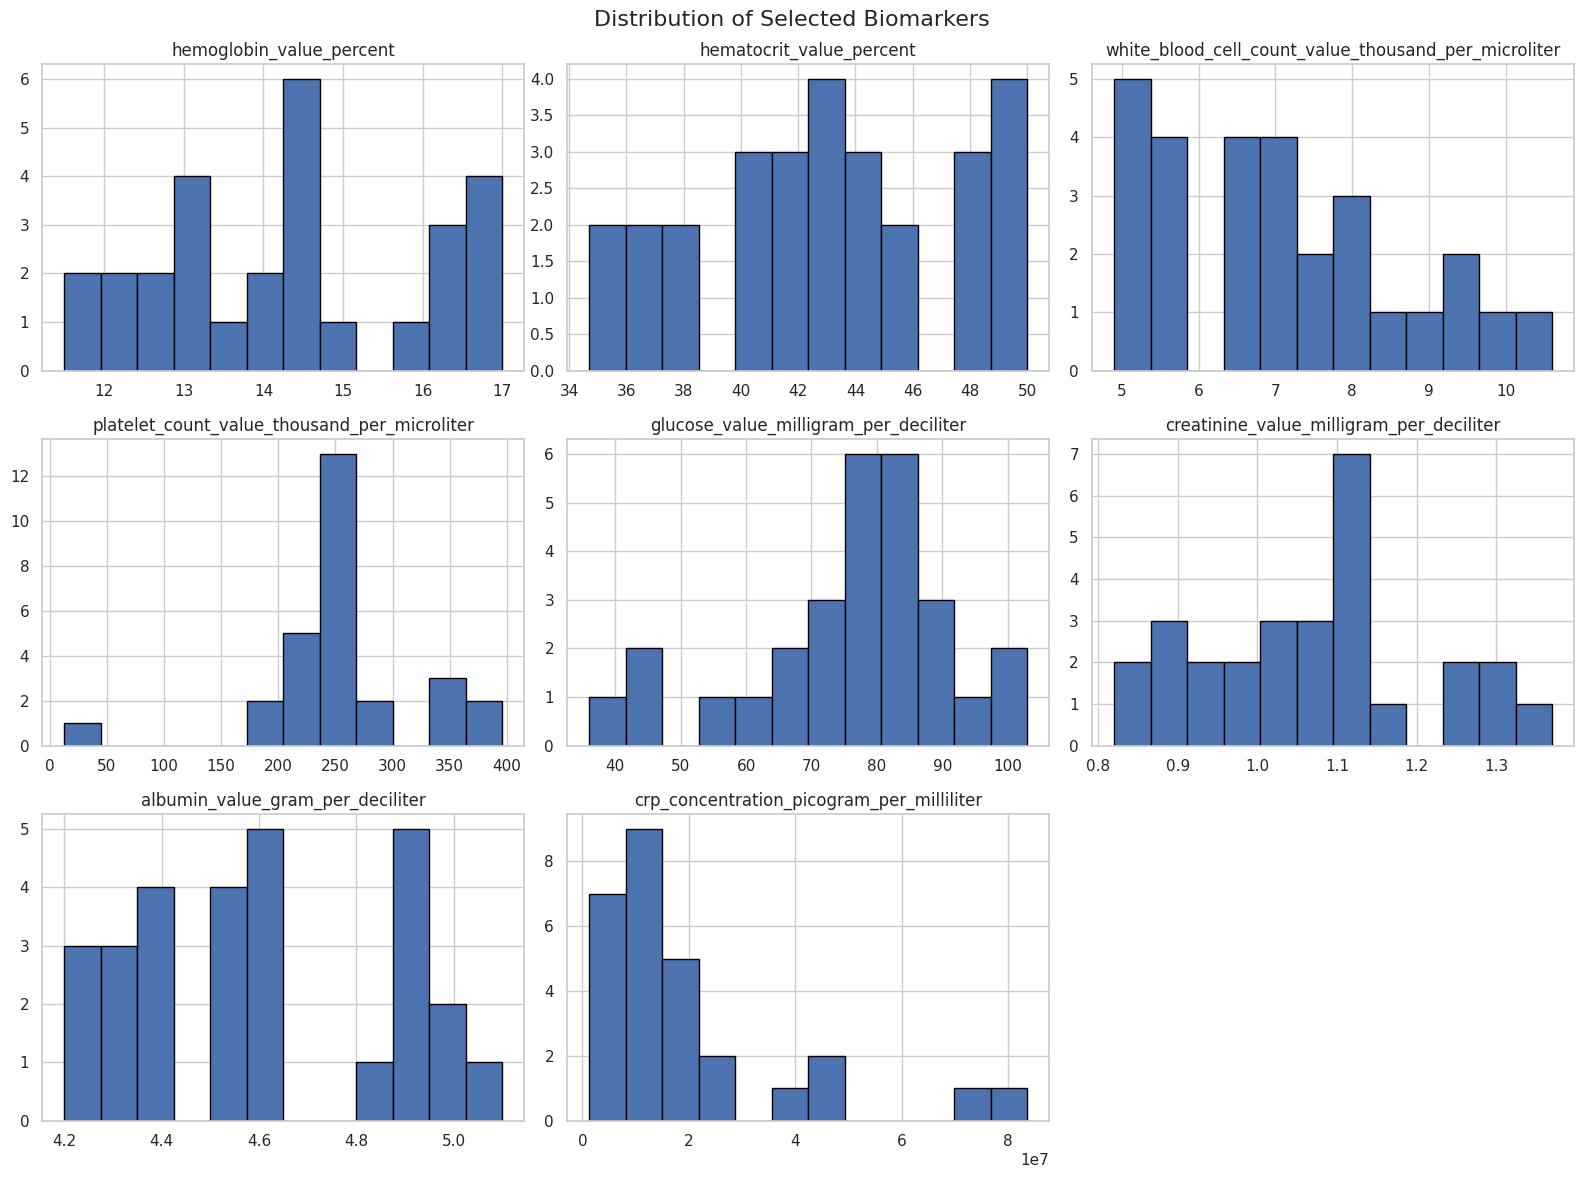


Biomarker distribution analysis completed successfully!
Results saved in: /content/final_research_data


In [119]:

# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# STEP 1: BIOMARKER DISTRIBUTIONS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Use the existing final research dataset
df = final_df.copy()

# Create output folder
output_folder = "/content/final_research_data"
os.makedirs(output_folder, exist_ok=True)

# Dataset overview
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

# Select important biomarkers
biomarkers = [
    "hemoglobin_value_percent",
    "hematocrit_value_percent",
    "white_blood_cell_count_value_thousand_per_microliter",
    "platelet_count_value_thousand_per_microliter",
    "glucose_value_milligram_per_deciliter",
    "creatinine_value_milligram_per_deciliter",
    "albumin_value_gram_per_deciliter",
    "crp_concentration_picogram_per_milliliter"
]

# Keep only available columns
biomarkers = [col for col in biomarkers if col in df.columns]

print("\nSelected biomarkers:")
print(biomarkers)

# Generate descriptive statistics for selected biomarkers
display(df[biomarkers].describe().T)

# Plot biomarker distributions
df[biomarkers].hist(
    bins=12,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Selected Biomarkers",
    fontsize=16
)
plt.tight_layout()

# Save histogram figure
plt.savefig(
    f"{output_folder}/Biomarker_Distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export biomarker statistics
df[biomarkers].describe().T.to_csv(
    f"{output_folder}/Biomarker_Distribution_Statistics.csv"
)

print("\nBiomarker distribution analysis completed successfully!")
print("Results saved in:", output_folder)


Pearson Correlation Matrix:


,hemoglobin_value_percent,hematocrit_value_percent,white_blood_cell_count_value_thousand_per_microliter,platelet_count_value_thousand_per_microliter,glucose_value_milligram_per_deciliter,creatinine_value_milligram_per_deciliter,albumin_value_gram_per_deciliter,crp_concentration_picogram_per_milliliter
hemoglobin_value_percent,1.000000,0.986453,0.262591,0.079753,0.074741,0.556892,0.260700,-0.005097
hematocrit_value_percent,0.986453,1.000000,0.304245,0.110252,0.066114,0.533761,0.263229,0.034813
white_blood_cell_count_value_thousand_per_microliter,0.262591,0.304245,1.000000,0.171762,-0.248550,-0.038431,-0.328245,0.379119
platelet_count_value_thousand_per_microliter,0.079753,0.110252,0.171762,1.000000,-0.249207,-0.155829,-0.019598,0.015528
glucose_value_milligram_per_deciliter,0.074741,0.066114,-0.248550,-0.249207,1.000000,0.186147,0.089824,0.176213
creatinine_value_milligram_per_deciliter,0.556892,0.533761,-0.038431,-0.155829,0.186147,1.000000,0.273901,-0.069561
albumin_value_gram_per_deciliter,0.260700,0.263229,-0.328245,-0.019598,0.089824,0.273901,1.000000,-0.411791
crp_concentration_picogram_per_milliliter,-0.005097,0.034813,0.379119,0.015528,0.176213,-0.069561,-0.411791,1.000000


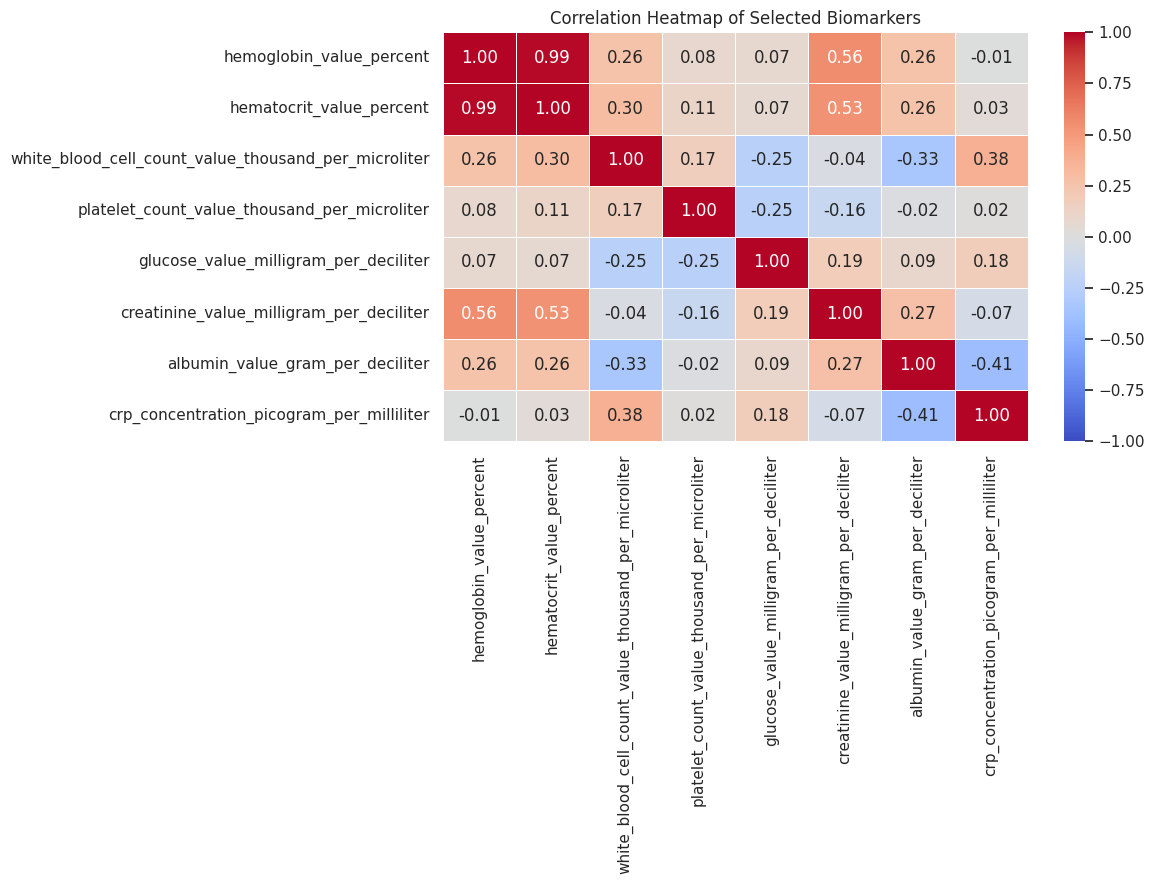

Correlation analysis completed successfully!


In [120]:

# ==========================================
# EDA STEP 2: CORRELATION ANALYSIS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Use existing final dataset
df = final_df.copy()

output_folder = "/content/final_research_data"
os.makedirs(output_folder, exist_ok=True)

# Select biomarkers
biomarkers = [
    "hemoglobin_value_percent",
    "hematocrit_value_percent",
    "white_blood_cell_count_value_thousand_per_microliter",
    "platelet_count_value_thousand_per_microliter",
    "glucose_value_milligram_per_deciliter",
    "creatinine_value_milligram_per_deciliter",
    "albumin_value_gram_per_deciliter",
    "crp_concentration_picogram_per_milliliter"
]

biomarkers = [col for col in biomarkers if col in df.columns]

# Calculate Pearson correlation
correlation_matrix = df[biomarkers].corr(method="pearson")

print("Pearson Correlation Matrix:")
display(correlation_matrix)

# Generate correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Selected Biomarkers")
plt.tight_layout()

# Save heatmap
plt.savefig(
    f"{output_folder}/Biomarker_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export correlation matrix
correlation_matrix.to_csv(
    f"{output_folder}/Biomarker_Correlation_Matrix.csv"
)

print("Correlation analysis completed successfully!")


,Biomarker,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Sample_Names
0,hemoglobin_value_percent,9.187500e+00,1.988750e+01,0,
1,hematocrit_value_percent,3.188750e+01,5.518750e+01,0,
2,white_blood_cell_count_value_thousand_per_micr...,1.762500e+00,1.166250e+01,0,
3,platelet_count_value_thousand_per_microliter,1.762500e+02,3.162500e+02,6,"C003_whole-blood_L-3_cbc, C003_whole-blood_L-4..."
4,glucose_value_milligram_per_deciliter,5.212500e+01,1.031250e+02,3,"C002_whole-blood_R+45_cbc, C003_whole-blood_R+..."
5,creatinine_value_milligram_per_deciliter,6.950000e-01,1.395000e+00,0,
6,albumin_value_gram_per_deciliter,3.650000e+00,5.650000e+00,0,
7,crp_concentration_picogram_per_milliliter,-1.142025e+07,4.156935e+07,4,"C003_whole-blood_L-3_cbc, C003_whole-blood_L-9..."


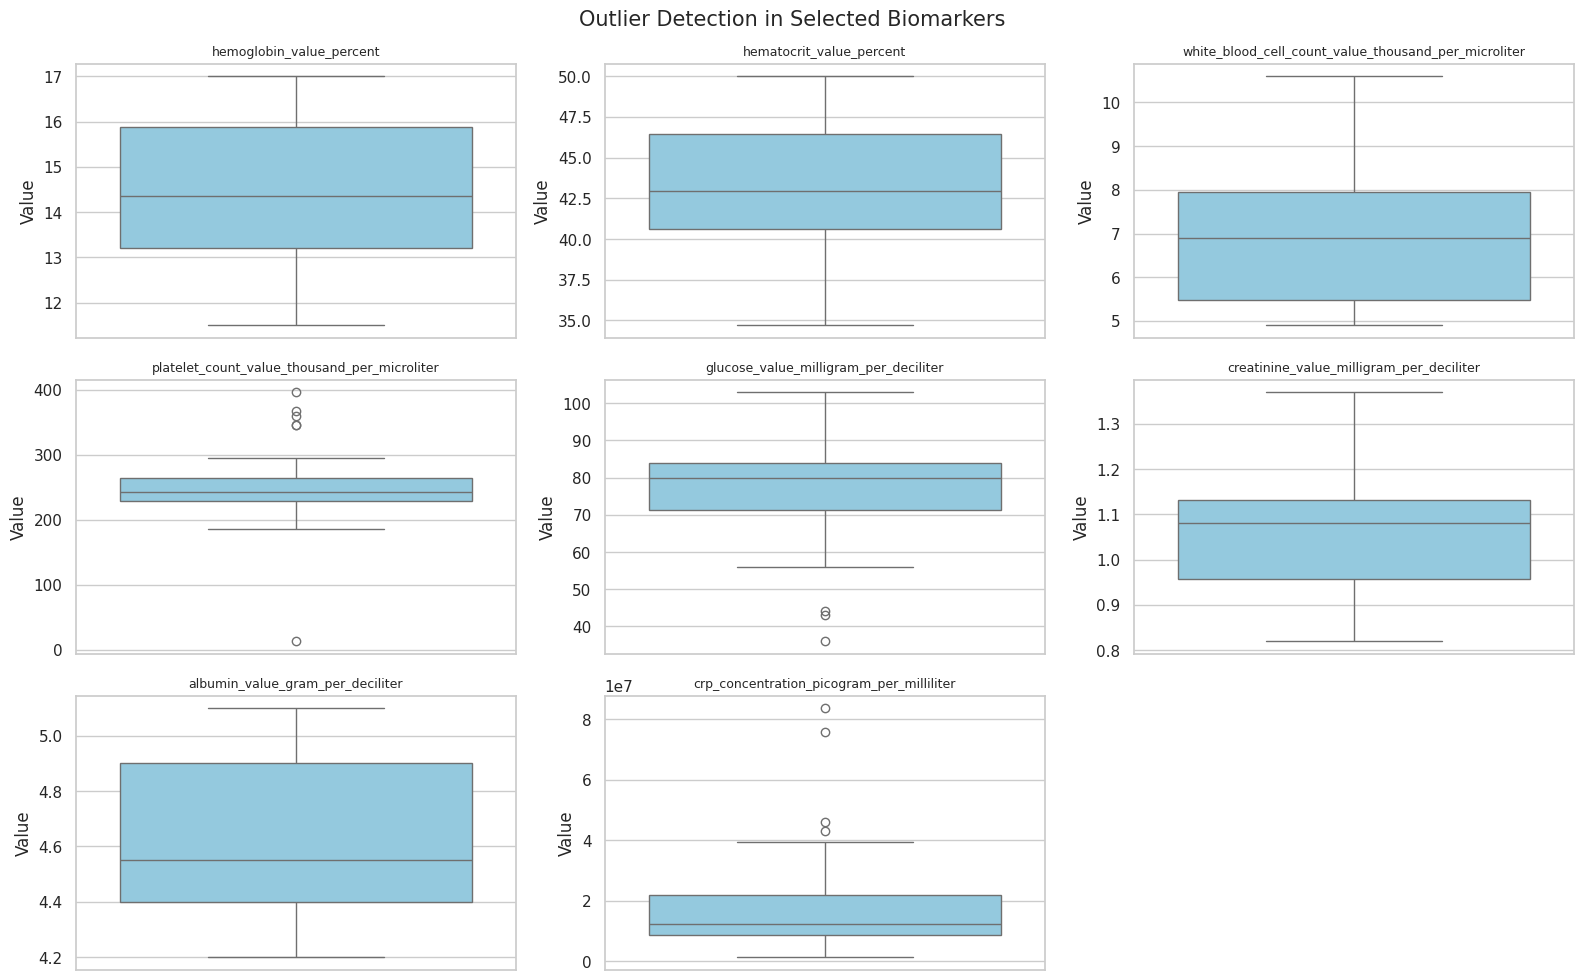

Outlier detection completed successfully!
Results saved in: /content/final_research_data

Original dataset remains unchanged.


In [121]:

# ==========================================
# EDA STEP 3: OUTLIER DETECTION
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = final_df.copy()

output_folder = "/content/final_research_data"
os.makedirs(output_folder, exist_ok=True)

# Select important biomarkers
biomarkers = [
    "hemoglobin_value_percent",
    "hematocrit_value_percent",
    "white_blood_cell_count_value_thousand_per_microliter",
    "platelet_count_value_thousand_per_microliter",
    "glucose_value_milligram_per_deciliter",
    "creatinine_value_milligram_per_deciliter",
    "albumin_value_gram_per_deciliter",
    "crp_concentration_picogram_per_milliliter"
]

biomarkers = [col for col in biomarkers if col in df.columns]

# Calculate outliers using IQR
outlier_results = []

for col in biomarkers:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Biomarker": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Sample_Names": ", ".join(
            outliers["Sample Name"].astype(str)
        )
    })

# Display results
outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

# Save outlier report
outlier_df.to_csv(
    f"{output_folder}/Outlier_Detection_Report.csv",
    index=False
)

# Generate boxplots
plt.figure(figsize=(16, 10))

for i, col in enumerate(biomarkers, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col, fontsize=9)
    plt.ylabel("Value")

plt.suptitle(
    "Outlier Detection in Selected Biomarkers",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    f"{output_folder}/Biomarker_Outlier_Boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Outlier detection completed successfully!")
print("Results saved in:", output_folder)

print("\nOriginal dataset remains unchanged.")


In [122]:

# ==========================================
# EDA STEP 4: INVESTIGATE OUTLIERS
# ==========================================

import pandas as pd
import numpy as np

df = final_df.copy()

biomarkers = [
    "platelet_count_value_thousand_per_microliter",
    "glucose_value_milligram_per_deciliter",
    "crp_concentration_picogram_per_milliliter"
]

for col in biomarkers:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ][["Sample Name", col]]

    print("\n" + "=" * 65)
    print("BIOMARKER:", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outlier observations:")

    display(outliers)

print("\nOutlier investigation completed!")



BIOMARKER: platelet_count_value_thousand_per_microliter
Lower limit: 176.25
Upper limit: 316.25
Outlier observations:


,Sample Name,platelet_count_value_thousand_per_microliter
14,C003_whole-blood_L-3_cbc,367.0
15,C003_whole-blood_L-44_cbc,345.0
16,C003_whole-blood_L-92_cbc,12.9
17,C003_whole-blood_R+1_cbc,359.0
19,C003_whole-blood_R+45_cbc,396.0
20,C003_whole-blood_R+82_cbc,345.0



BIOMARKER: glucose_value_milligram_per_deciliter
Lower limit: 52.125
Upper limit: 103.125
Outlier observations:


,Sample Name,glucose_value_milligram_per_deciliter
12,C002_whole-blood_R+45_cbc,44
19,C003_whole-blood_R+45_cbc,36
26,C004_whole-blood_R+45_cbc,43



BIOMARKER: crp_concentration_picogram_per_milliliter
Lower limit: -11420250.0
Upper limit: 41569350.0
Outlier observations:


,Sample Name,crp_concentration_picogram_per_milliliter
14,C003_whole-blood_L-3_cbc,42838000
16,C003_whole-blood_L-92_cbc,75749000
17,C003_whole-blood_R+1_cbc,83617000
25,C004_whole-blood_R+194_cbc,46006000



Outlier investigation completed!


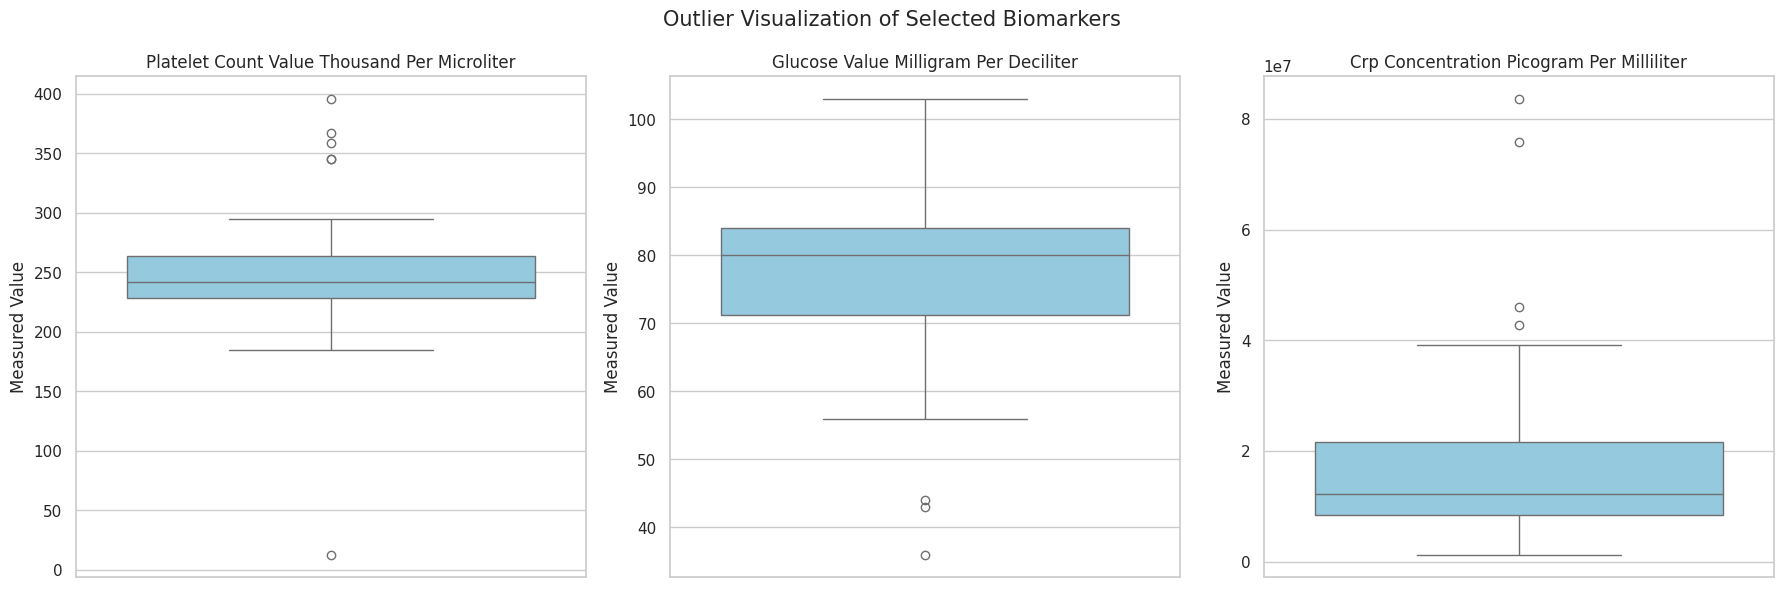

Outlier visualization completed successfully!


In [123]:

# Outlier visualization using boxplots

import matplotlib.pyplot as plt
import seaborn as sns

# Biomarkers identified with outliers
outlier_biomarkers = [
    "platelet_count_value_thousand_per_microliter",
    "glucose_value_milligram_per_deciliter",
    "crp_concentration_picogram_per_milliliter"
]

# Create boxplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, biomarker in zip(axes, outlier_biomarkers):
    sns.boxplot(y=df[biomarker], ax=ax, color="skyblue")
    ax.set_title(biomarker.replace("_", " ").title())
    ax.set_ylabel("Measured Value")

plt.suptitle("Outlier Visualization of Selected Biomarkers", fontsize=15)
plt.tight_layout()

# Save figure
plt.savefig(
    "/content/final_research_data/Outlier_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Outlier visualization completed successfully!")


In [124]:

# Data quality assessment

import pandas as pd
import numpy as np

# Check missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

print("MISSING VALUE SUMMARY")
display(missing_summary)

# Check outlier counts
outlier_summary = []

for biomarker in outlier_biomarkers:
    Q1 = df[biomarker].quantile(0.25)
    Q3 = df[biomarker].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[biomarker] < lower) |
        (df[biomarker] > upper)
    ]

    outlier_summary.append({
        "Biomarker": biomarker,
        "Outlier_Count": len(outliers),
        "Lower_Bound": lower,
        "Upper_Bound": upper
    })

outlier_summary = pd.DataFrame(outlier_summary)

print("\nOUTLIER SUMMARY")
display(outlier_summary)

# Export results
missing_summary.to_csv(
    "/content/final_research_data/Missing_Value_Summary.csv"
)

outlier_summary.to_csv(
    "/content/final_research_data/Outlier_Summary.csv",
    index=False
)

print("\nData quality assessment completed successfully!")


MISSING VALUE SUMMARY


,Missing_Count,Missing_Percentage
bun_to_creatinine_ratio_value,22,78.57
mchc_value_grams_per_deciliter,4,14.29
mchc_range_min_grams_per_deciliter,4,14.29
mchc_range_max_grams_per_deciliter,4,14.29
mch_value_picogram,2,7.14
mch_range_min_picogram,2,7.14
mch_range_max_picogram,2,7.14
mcv_range_min_femtoliter,1,3.57
mcv_value_femtoliter,1,3.57
mcv_range_max_femtoliter,1,3.57



OUTLIER SUMMARY


,Biomarker,Outlier_Count,Lower_Bound,Upper_Bound
0,platelet_count_value_thousand_per_microliter,6,1.762500e+02,3.162500e+02
1,glucose_value_milligram_per_deciliter,3,5.212500e+01,1.031250e+02
2,crp_concentration_picogram_per_milliliter,4,-1.142025e+07,4.156935e+07



Data quality assessment completed successfully!


In [125]:

# Missing value handling for modeling preparation

import pandas as pd
import numpy as np

# Create a separate copy; preserve original dataset
model_df = df.copy()

# Identify columns with excessive missing values
high_missing_columns = [
    col for col in model_df.columns
    if model_df[col].isnull().mean() > 0.50
]

print("Columns excluded due to excessive missingness:")
print(high_missing_columns)

# Exclude columns with more than 50% missing values
model_df = model_df.drop(columns=high_missing_columns)

# Identify measured biomarker columns
# Exclude sample ID and laboratory reference-range columns
measurement_columns = [
    col for col in model_df.select_dtypes(include="number").columns
    if "_range_min_" not in col
    and "_range_max_" not in col
    and not col.endswith("_range_min")
    and not col.endswith("_range_max")
]

# Median imputation for measured values only
for col in measurement_columns:
    if model_df[col].isnull().any():
        model_df[col] = model_df[col].fillna(
            model_df[col].median()
        )

# Check remaining missing values
print("\nFinal modeling dataset shape:", model_df.shape)
print("Remaining missing values:", model_df.isnull().sum().sum())

# Export modeling dataset
model_df.to_csv(
    "/content/final_research_data/Modeling_Dataset.csv",
    index=False
)

print("\nModeling dataset saved successfully!")


Columns excluded due to excessive missingness:
['bun_to_creatinine_ratio_value']

Final modeling dataset shape: (28, 276)
Remaining missing values: 16

Modeling dataset saved successfully!


In [126]:

# Identify remaining missing values

remaining_missing = model_df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Remaining missing-value columns:")
display(remaining_missing)

print("\nTotal remaining missing values:",
      model_df.isnull().sum().sum())

print("\nMissing values by column type:")

for col in remaining_missing.index:
    print(
        col,
        "| Missing:",
        remaining_missing[col],
        "| Type:",
        "Reference range" if "range" in col.lower()
        else "Measured variable"
    )


Remaining missing-value columns:


,0
mchc_range_max_grams_per_deciliter,4
mchc_range_min_grams_per_deciliter,4
mch_range_max_picogram,2
mch_range_min_picogram,2
mcv_range_min_femtoliter,1
mcv_range_max_femtoliter,1
bun_to_creatinine_ratio_range_min,1
bun_to_creatinine_ratio_range_max,1



Total remaining missing values: 16

Missing values by column type:
mchc_range_max_grams_per_deciliter | Missing: 4 | Type: Reference range
mchc_range_min_grams_per_deciliter | Missing: 4 | Type: Reference range
mch_range_max_picogram | Missing: 2 | Type: Reference range
mch_range_min_picogram | Missing: 2 | Type: Reference range
mcv_range_min_femtoliter | Missing: 1 | Type: Reference range
mcv_range_max_femtoliter | Missing: 1 | Type: Reference range
bun_to_creatinine_ratio_range_min | Missing: 1 | Type: Reference range
bun_to_creatinine_ratio_range_max | Missing: 1 | Type: Reference range


In [127]:

# Final modeling dataset validation

import pandas as pd
import numpy as np

print("FINAL DATASET VALIDATION")
print("=" * 45)

# Dataset dimensions
print("Dataset shape:", model_df.shape)

# Sample uniqueness
print("Unique samples:", model_df["Sample Name"].nunique())

# Duplicate rows
print("Duplicate rows:", model_df.duplicated().sum())

# Duplicate sample IDs
print("Duplicate sample IDs:",
      model_df["Sample Name"].duplicated().sum())

# Missing measured values
measurement_columns = [
    col for col in model_df.select_dtypes(include="number").columns
    if "range" not in col.lower()
]

missing_measurements = (
    model_df[measurement_columns].isnull().sum().sum()
)

print("Missing measured values:", missing_measurements)

# Missing reference-range values
reference_columns = [
    col for col in model_df.columns
    if "range" in col.lower()
]

missing_reference_values = (
    model_df[reference_columns].isnull().sum().sum()
)

print("Missing reference-range values:",
      missing_reference_values)

# Save final validated dataset
model_df.to_csv(
    "/content/final_research_data/Final_Modeling_Dataset.csv",
    index=False
)

print("\nFinal modeling dataset exported successfully!")


FINAL DATASET VALIDATION
Dataset shape: (28, 276)
Unique samples: 28
Duplicate rows: 0
Duplicate sample IDs: 0
Missing measured values: 0
Missing reference-range values: 16

Final modeling dataset exported successfully!


In [128]:

# Feature selection: variance and correlation analysis

import pandas as pd
import numpy as np

# Load validated modeling dataset
df_model = pd.read_csv(
    "/content/final_research_data/Final_Modeling_Dataset.csv"
)

# Select numeric features
numeric_features = df_model.select_dtypes(
    include="number"
)

# Exclude laboratory reference-range columns
feature_columns = [
    col for col in numeric_features.columns
    if "range" not in col.lower()
]

features = numeric_features[feature_columns]

# 1. Identify zero-variance features
zero_variance = [
    col for col in features.columns
    if features[col].nunique() <= 1
]

print("ZERO-VARIANCE FEATURES")
print("Count:", len(zero_variance))
print(zero_variance)

# 2. Calculate correlation matrix
correlation_matrix = features.corr(method="pearson")

# 3. Identify highly correlated feature pairs
correlation_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) >= 0.90:
            correlation_pairs.append({
                "Feature_1": correlation_matrix.columns[i],
                "Feature_2": correlation_matrix.columns[j],
                "Correlation": corr_value
            })

correlation_df = pd.DataFrame(correlation_pairs)

print("\nHIGHLY CORRELATED FEATURE PAIRS")
print("Count:", len(correlation_df))

display(correlation_df.head(30))

# Export results
correlation_df.to_csv(
    "/content/final_research_data/Highly_Correlated_Features.csv",
    index=False
)

print("\nFeature correlation analysis completed!")


ZERO-VARIANCE FEATURES
Count: 0
[]

HIGHLY CORRELATED FEATURE PAIRS
Count: 179


,Feature_1,Feature_2,Correlation
0,hematocrit_value_percent,hemoglobin_value_percent,0.986453
1,hematocrit_value_percent,red_blood_cell_count_value_million_per_microliter,0.974981
2,hemoglobin_value_percent,red_blood_cell_count_value_million_per_microliter,0.971506
3,lymphocytes_value_percent,neutrophils_value_percent,-0.907774
4,mpv_value_femtoliter,rdw_value_percent,0.994085
5,alt_max_units_per_liter,ast_max_units_per_liter,0.910987
6,egfr_african_american_value_milliliter_per_min...,egfr_non_african_american_value_milliliter_per...,0.999233
7,6ckine_concentration_picogram_per_milliliter,6ckine_percent,1.000000
8,bca_1_concentration_picogram_per_milliliter,bca_1_percent,1.000000
9,ctack_concentration_picogram_per_milliliter,ctack_percent,1.000000



Feature correlation analysis completed!


In [129]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
OUT = "/content/final_research_data"
os.makedirs(OUT, exist_ok=True)

ml_df = model_df.copy()

parsed = ml_df["Sample_ID"].str.extract(r"^(C\d+)_([LR])([+-]\d+)$")
assert parsed.notna().all().all(), "Sample_ID format not recognised"
ml_df["Crew"] = parsed[0]
ml_df["Day"] = pd.to_numeric(parsed[2]).astype(int)
ml_df["Timepoint"] = parsed[1] + parsed[2]
ml_df["Phase"] = np.where(parsed[1] == "L", "Pre-flight", "Post-flight")
ml_df = ml_df.sort_values(["Crew", "Day"]).reset_index(drop=True)
tp_order = ml_df.drop_duplicates("Timepoint").sort_values("Day")["Timepoint"].tolist()
print("Timepoint order:", tp_order)
print(ml_df.groupby("Crew").size().to_dict())

# CRP: pg/mL -> mg/L
ml_df["crp_mg_per_L"] = ml_df["crp_concentration_picogram_per_milliliter"] / 1e6

# Suspect platelet value (12.9) -> treat as data-entry error
plt_col = "platelet_count_value_thousand_per_microliter"
suspect = ml_df[plt_col] < 50
print("\nSuspect platelet values (likely data-entry error):")
print(ml_df.loc[suspect, ["Sample_ID", plt_col]])
ml_df.loc[suspect, plt_col] = np.nan
ml_df[plt_col] = ml_df.groupby("Crew")[plt_col].transform(lambda s: s.fillna(s.median()))

def find_col(prefix):
    hits = [c for c in ml_df.columns if c.startswith(prefix) and "range" not in c]
    return hits[0] if hits else None

core_spec = [
    ("hemoglobin_value_percent", "Hemoglobin", "g/dL", "Blood / cardiovascular"),
    ("hematocrit_value_percent", "Hematocrit", "%", "Blood / cardiovascular"),
    ("white_blood_cell_count_value_thousand_per_microliter", "White blood cells", "x10^3/uL", "Immune / radiation awareness"),
    (find_col("lymphocytes_value"), "Lymphocytes", "%", "Immune / radiation awareness"),
    ("platelet_count_value_thousand_per_microliter", "Platelets", "x10^3/uL", "Blood / cardiovascular"),
    ("glucose_value_milligram_per_deciliter", "Glucose", "mg/dL", "Metabolic / stress"),
    ("creatinine_value_milligram_per_deciliter", "Creatinine", "mg/dL", "Muscle / kidney"),
    ("albumin_value_gram_per_deciliter", "Albumin", "g/dL", "Nutrition / muscle"),
    (find_col("alkaline_phosphatase_value"), "Alkaline phosphatase", "U/L", "Bone / muscle"),
    (find_col("calcium_value"), "Calcium", "mg/dL", "Bone / muscle"),
    ("crp_mg_per_L", "C-reactive protein", "mg/L", "Inflammation / stress"),
]
core = {c: (l, u, cat) for c, l, u, cat in core_spec if c is not None and c in ml_df.columns}
core_cols = list(core.keys())
print("\nCore biomarkers used:", [v[0] for v in core.values()])

def is_feature(c):
    cl = c.lower()
    if any(k in cl for k in ["range", "_max_", "_min_"]) or cl.endswith(("_max", "_min")):
        return False
    return ("_value" in cl) or ("_concentration_" in cl)

feature_cols = [c for c in ml_df.select_dtypes("number").columns if is_feature(c)]
# use CRP in mg/L (converted) instead of the raw pg/mL column
feature_cols = [c for c in feature_cols if c != "crp_concentration_picogram_per_milliliter"]
feature_cols.append("crp_mg_per_L")
ml_df[feature_cols] = ml_df[feature_cols].fillna(ml_df[feature_cols].median())
feature_cols = [c for c in feature_cols if ml_df[c].nunique() > 1]
print("Number of ML features:", len(feature_cols), "| Samples:", len(ml_df))

Timepoint order: ['L-92', 'L-44', 'L-3', 'R+1', 'R+45', 'R+82', 'R+194']
{'C001': 7, 'C002': 7, 'C003': 7, 'C004': 7}

Suspect platelet values (likely data-entry error):
    Sample_ID  platelet_count_value_thousand_per_microliter
14  C003_L-92                                          12.9

Core biomarkers used: ['Hemoglobin', 'Hematocrit', 'White blood cells', 'Lymphocytes', 'Platelets', 'Glucose', 'Creatinine', 'Albumin', 'Alkaline phosphatase', 'Calcium', 'C-reactive protein']
Number of ML features: 118 | Samples: 28


In [130]:

pre = ml_df[ml_df["Phase"] == "Pre-flight"]
base_mean = pre.groupby("Crew")[feature_cols].mean()
base_sd = pre.groupby("Crew")[feature_cols].std(ddof=1)
floor = 0.05 * base_mean.abs()                 # avoids tiny SD from only 3 baseline points
base_sd = base_sd.where(base_sd > floor, floor)

bm = base_mean.loc[ml_df["Crew"]].values
bs = base_sd.loc[ml_df["Crew"]].values
vals = ml_df[feature_cols].values

with np.errstate(divide="ignore", invalid="ignore"):
    Z = pd.DataFrame((vals - bm) / bs, columns=feature_cols, index=ml_df.index)
    PCT = pd.DataFrame((vals - bm) / np.abs(bm) * 100, columns=feature_cols, index=ml_df.index)
Z = Z.replace([np.inf, -np.inf], np.nan).fillna(0).clip(-10, 10)
PCT = PCT.replace([np.inf, -np.inf], np.nan).fillna(0)

# Deviation Index = average |z| of the core biomarkers (easy to explain)
ml_df["Deviation_Index"] = Z[core_cols].abs().mean(axis=1)
print("\nDeviation Index by timepoint (mean across crew):")
print(ml_df.groupby("Timepoint")["Deviation_Index"].mean().reindex(tp_order).round(2))


Deviation Index by timepoint (mean across crew):
Timepoint
L-92     0.57
L-44     0.56
L-3      0.65
R+1      1.00
R+45     1.19
R+82     0.99
R+194    1.27
Name: Deviation_Index, dtype: float64


/tmp/ipykernel_439/3460357810.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ml_df["Deviation_Index"] = Z[core_cols].abs().mean(axis=1)


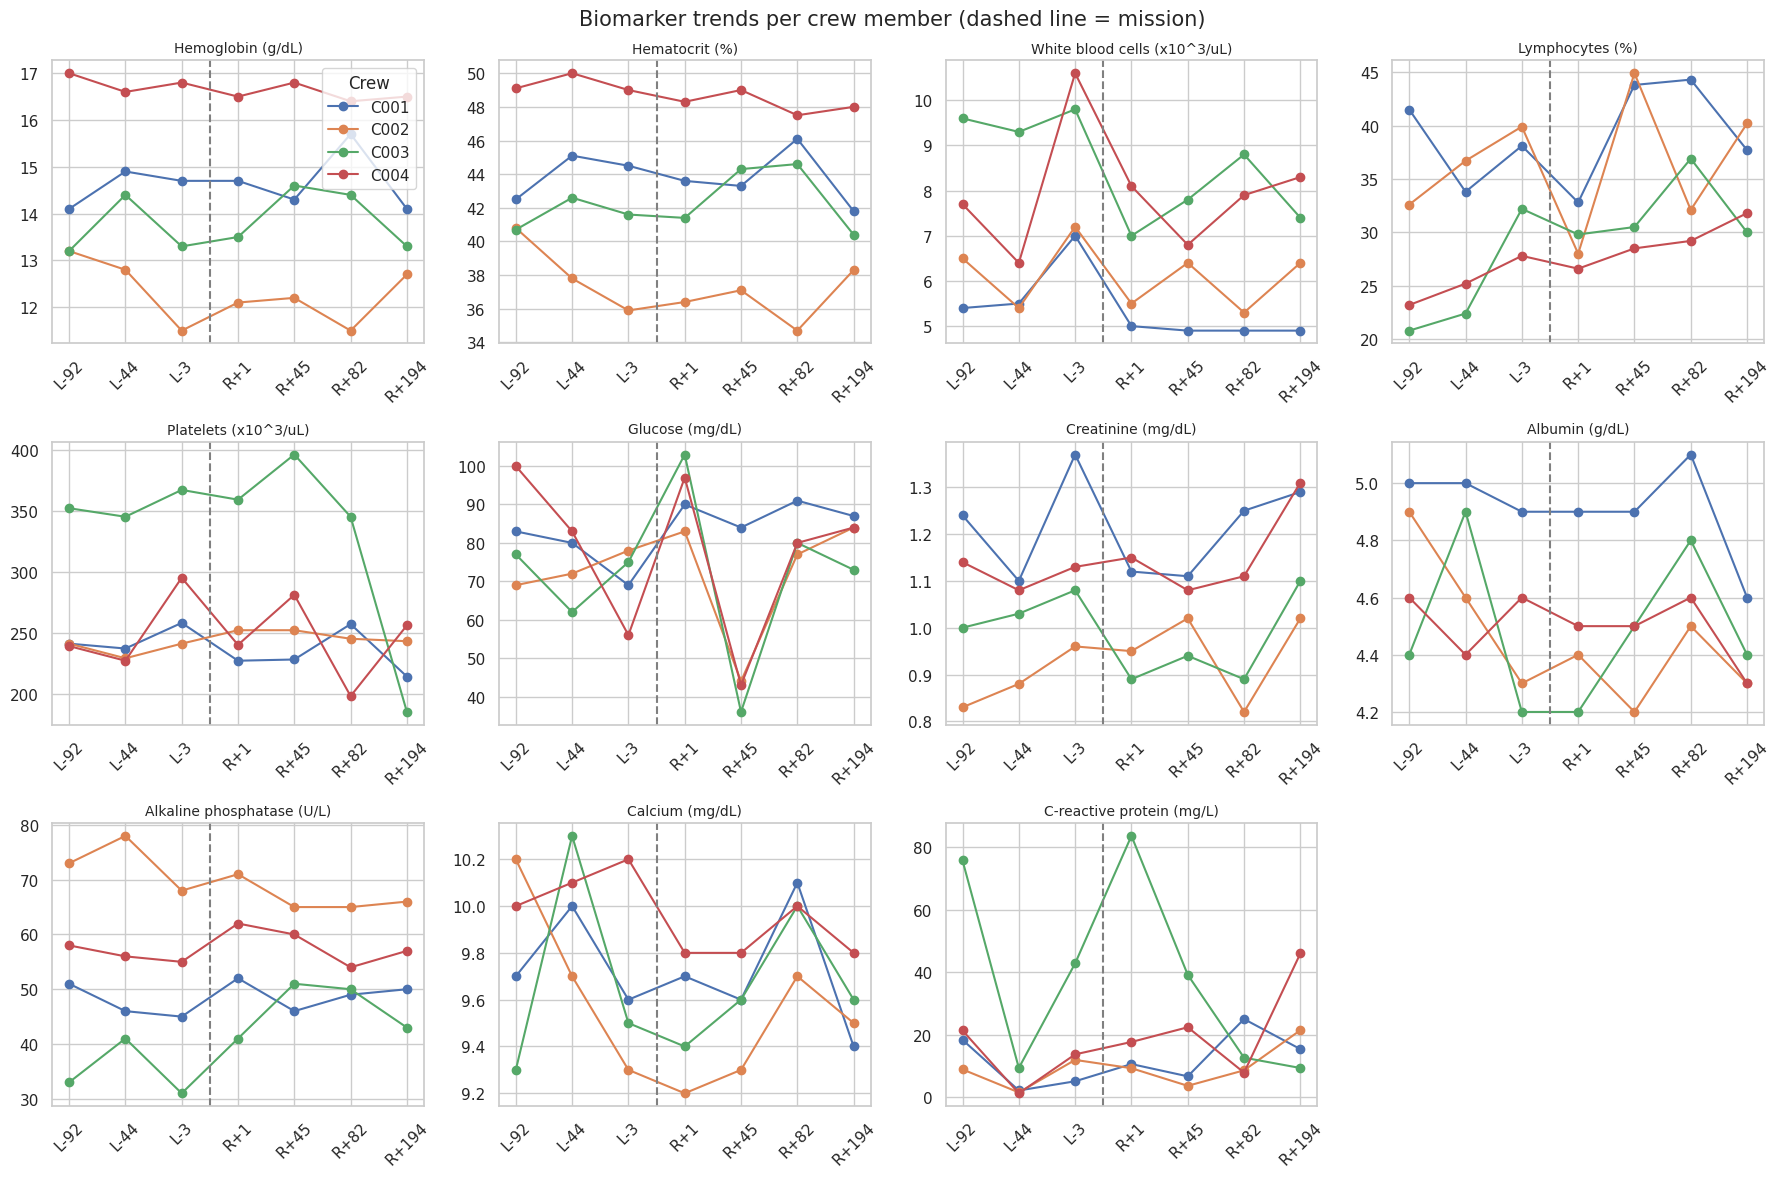

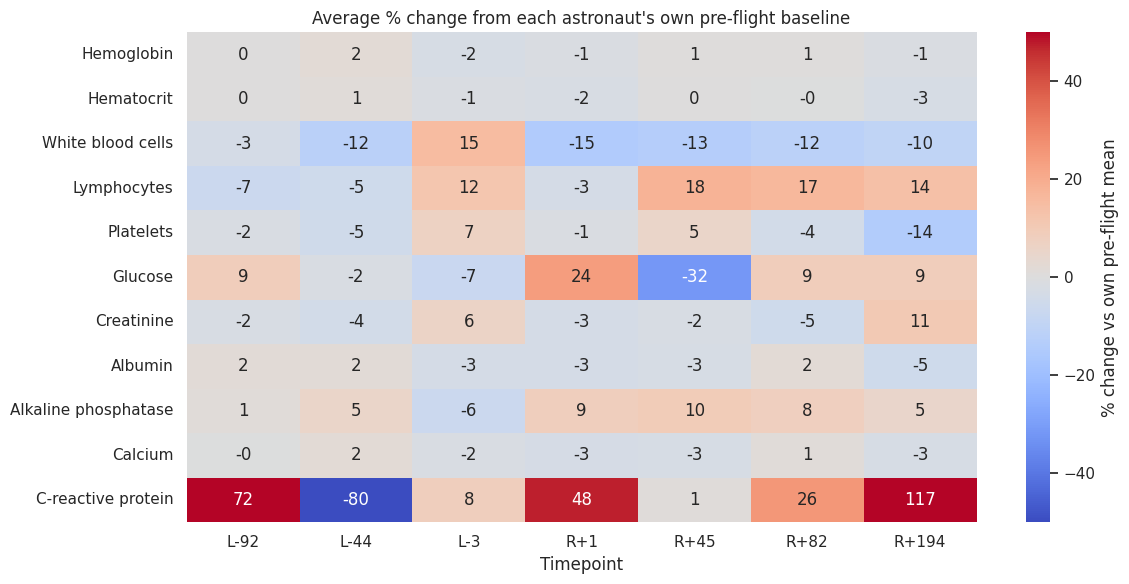

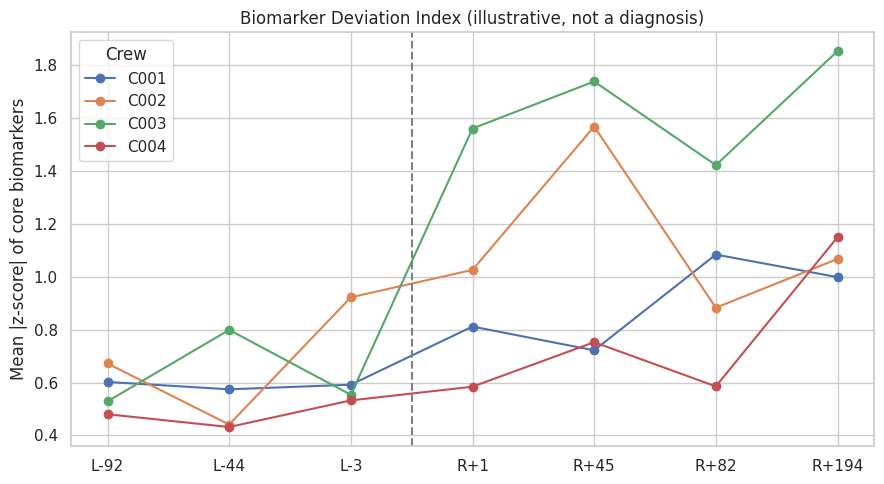

In [131]:

n = len(core_cols); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes = axes.ravel()
for ax, col in zip(axes, core_cols):
    for crew, g in ml_df.groupby("Crew"):
        g = g.sort_values("Day")
        ax.plot(g["Timepoint"], g[col], marker="o", label=crew)
    ax.axvline(2.5, ls="--", color="gray")
    ax.set_title(f"{core[col][0]} ({core[col][1]})", fontsize=10)
    ax.tick_params(axis="x", rotation=45)
for ax in axes[n:]:
    ax.axis("off")
axes[0].legend(title="Crew")
plt.suptitle("Biomarker trends per crew member (dashed line = mission)", fontsize=15)
plt.tight_layout()
plt.savefig(f"{OUT}/Trends_Per_Crew.png", dpi=200, bbox_inches="tight")
plt.show()

tmp = PCT[core_cols].copy()
tmp["Timepoint"] = ml_df["Timepoint"]
hm = tmp.groupby("Timepoint").mean().reindex(tp_order)
hm.columns = [core[c][0] for c in hm.columns]
plt.figure(figsize=(12, 6))
sns.heatmap(hm.T, annot=True, fmt=".0f", cmap="coolwarm", center=0, vmin=-50, vmax=50,
            cbar_kws={"label": "% change vs own pre-flight mean"})
plt.title("Average % change from each astronaut's own pre-flight baseline")
plt.tight_layout()
plt.savefig(f"{OUT}/PctChange_Heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
for crew, g in ml_df.groupby("Crew"):
    g = g.sort_values("Day")
    plt.plot(g["Timepoint"], g["Deviation_Index"], marker="o", label=crew)
plt.axvline(2.5, ls="--", color="gray")
plt.ylabel("Mean |z-score| of core biomarkers")
plt.title("Biomarker Deviation Index (illustrative, not a diagnosis)")
plt.legend(title="Crew")
plt.tight_layout()
plt.savefig(f"{OUT}/Deviation_Index.png", dpi=200, bbox_inches="tight")
plt.show()


Biomarkers that shifted in the SAME direction in all crew at R+1:
                                                    mean_z  mean_pct_change  consistent_crew
il_6_concentration_picogram_per_milliliter            5.10            90.06                4
mcp_1_concentration_picogram_per_milliliter           4.05            97.22                4
monocytes_value_percent                               3.45            25.52                4
il_10_concentration_picogram_per_milliliter           2.33            54.50                4
il_27_concentration_picogram_per_milliliter           2.29            41.25                4
glucose_value_milligram_per_deciliter                 2.14            24.06                4
white_blood_cell_count_value_thousand_per_micro...   -1.87           -14.57                4
ip_10_concentration_picogram_per_milliliter           1.62            55.64                4
tnfα_concentration_picogram_per_milliliter            1.30            25.89                4
mip

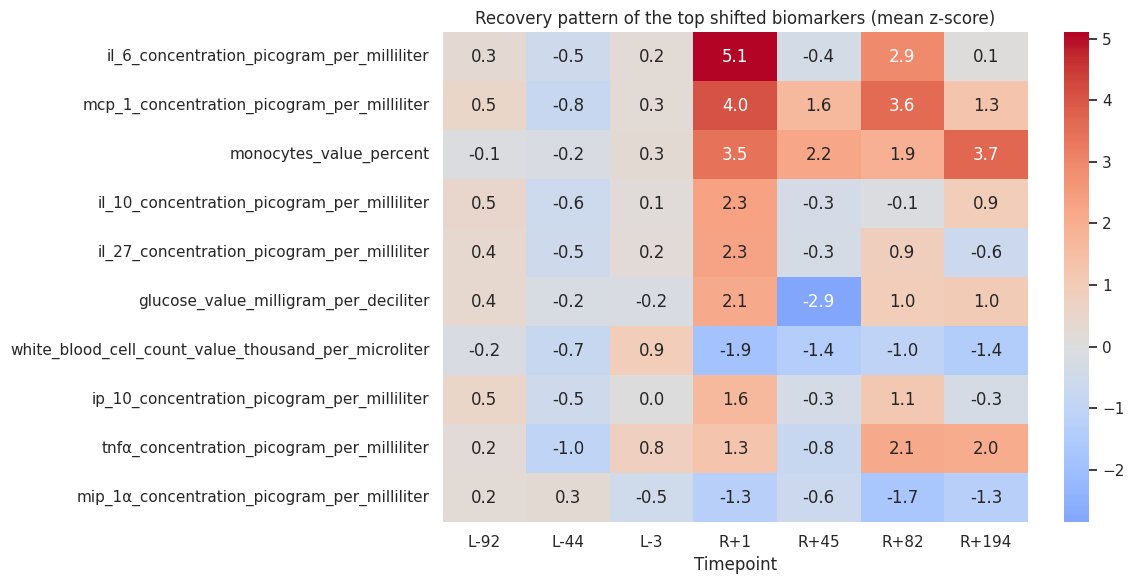

In [132]:

r1 = (ml_df["Timepoint"] == "R+1").values
summary = pd.DataFrame({
    "mean_z": Z.loc[r1].mean(),
    "mean_pct_change": PCT.loc[r1].mean(),
    "n_up": (Z.loc[r1] > 0).sum(),
    "n_down": (Z.loc[r1] < 0).sum(),
})
summary["consistent_crew"] = summary[["n_up", "n_down"]].max(axis=1)
summary["abs_z"] = summary["mean_z"].abs()
top = (summary[summary["consistent_crew"] == r1.sum()]
       .sort_values("abs_z", ascending=False).head(15))
pd.set_option("display.width", 200)
print("\nBiomarkers that shifted in the SAME direction in all crew at R+1:")
print(top[["mean_z", "mean_pct_change", "consistent_crew"]].round(2))
top.to_csv(f"{OUT}/Top_Shifted_Biomarkers_R1.csv")

if len(top) > 0:
    rec = Z[top.index[:10]].groupby(ml_df["Timepoint"]).mean().reindex(tp_order)
    plt.figure(figsize=(12, 6))
    sns.heatmap(rec.T, cmap="coolwarm", center=0, annot=True, fmt=".1f")
    plt.title("Recovery pattern of the top shifted biomarkers (mean z-score)")
    plt.tight_layout()
    plt.savefig(f"{OUT}/Recovery_Pattern.png", dpi=200, bbox_inches="tight")
    plt.show()

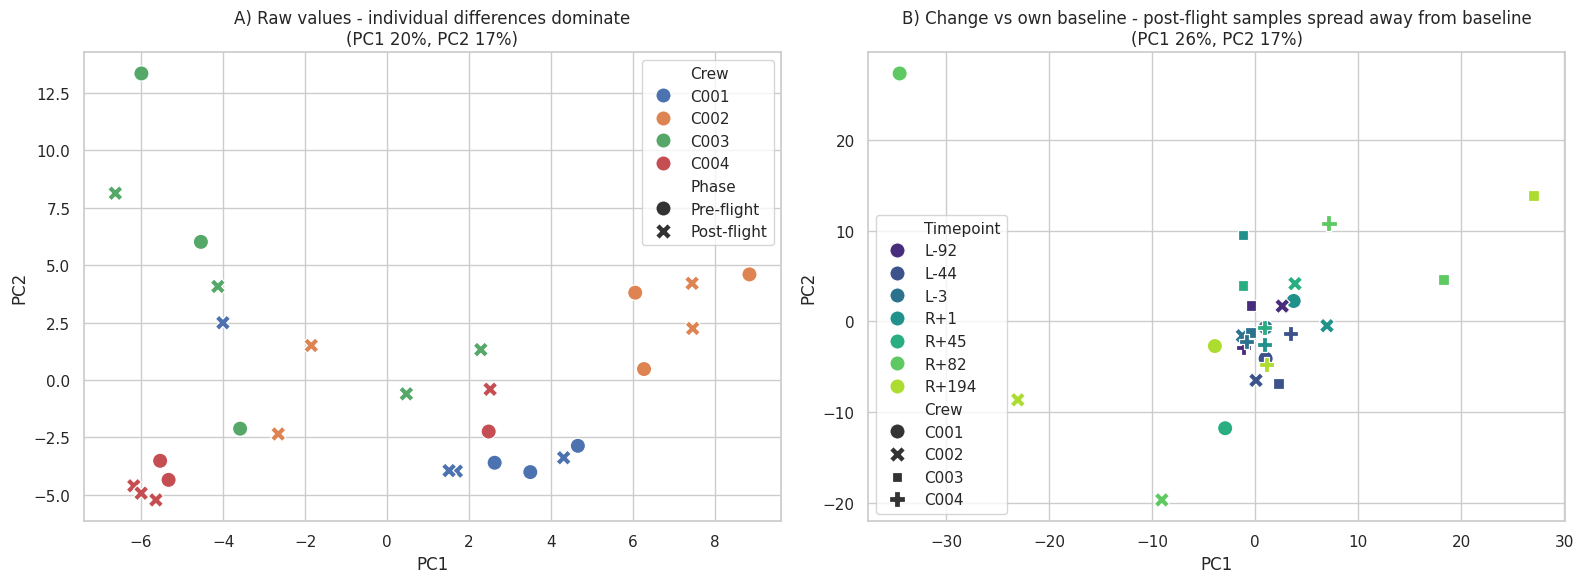

In [133]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xraw = StandardScaler().fit_transform(ml_df[feature_cols])
pc_raw = PCA(n_components=2, random_state=42).fit(Xraw)
P1 = pc_raw.transform(Xraw)
pc_adj = PCA(n_components=2, random_state=42).fit(Z.values)
P2 = pc_adj.transform(Z.values)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=P1[:, 0], y=P1[:, 1], hue=ml_df["Crew"], style=ml_df["Phase"], s=120, ax=ax[0])
ax[0].set_title(f"A) Raw values - individual differences dominate\n"
                f"(PC1 {pc_raw.explained_variance_ratio_[0]*100:.0f}%, PC2 {pc_raw.explained_variance_ratio_[1]*100:.0f}%)")
pal = sns.color_palette("viridis", len(tp_order))
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=ml_df["Timepoint"], hue_order=tp_order,
                palette=pal, style=ml_df["Crew"], s=120, ax=ax[1])
ax[1].set_title(f"B) Change vs own baseline - post-flight samples spread away from baseline\n"
                f"(PC1 {pc_adj.explained_variance_ratio_[0]*100:.0f}%, PC2 {pc_adj.explained_variance_ratio_[1]*100:.0f}%)")
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout()
plt.savefig(f"{OUT}/PCA_Raw_vs_Baseline_Adjusted.png", dpi=200, bbox_inches="tight")
plt.show()


Leave-one-astronaut-out results (pre-flight vs R+1)
Balanced accuracy: 0.833 | AUC: 0.958
Confusion matrix [rows=true, cols=pred]:
 [[11  1]
 [ 1  3]]
Permutation-test p-value: 0.025 (small = better than chance)


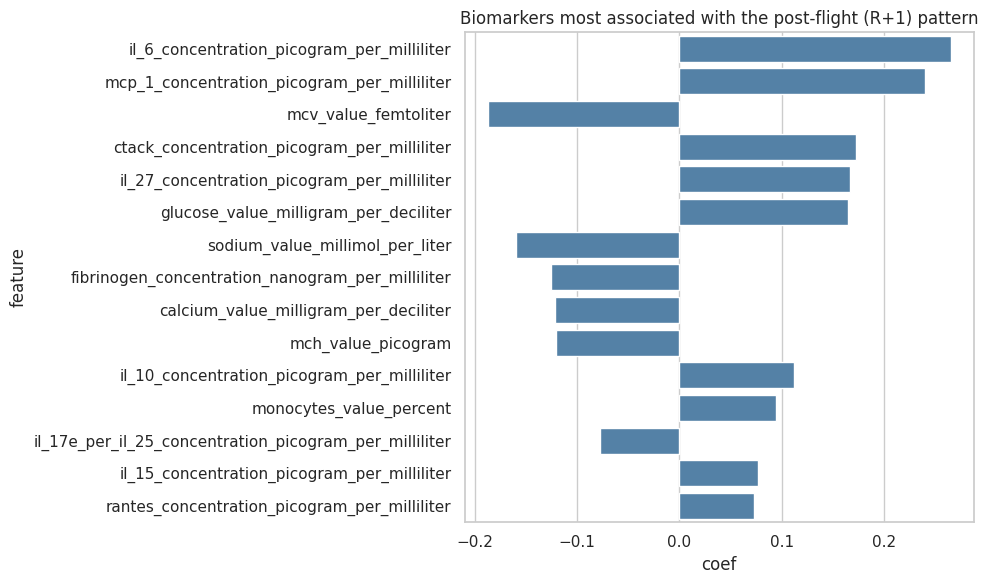

In [134]:

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, confusion_matrix

sub = ml_df[ml_df["Timepoint"].isin(["L-92", "L-44", "L-3", "R+1"])].reset_index(drop=True)
X = sub[feature_cols].values
y = (sub["Timepoint"] == "R+1").astype(int).values
groups = sub["Crew"].values

def make_pipe():
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k=20)),   # selection happens INSIDE each fold (no leakage)
        ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)),
    ])

def logo_scores(y_vec):
    pred = np.zeros(len(y_vec), dtype=int)
    prob = np.zeros(len(y_vec))
    for tr, te in LeaveOneGroupOut().split(X, y_vec, groups):
        m = make_pipe().fit(X[tr], y_vec[tr])
        pred[te] = m.predict(X[te])
        prob[te] = m.predict_proba(X[te])[:, 1]
    return pred, prob

pred, prob = logo_scores(y)
obs_bacc = balanced_accuracy_score(y, pred)
obs_auc = roc_auc_score(y, prob)
print("\nLeave-one-astronaut-out results (pre-flight vs R+1)")
print("Balanced accuracy:", round(obs_bacc, 3), "| AUC:", round(obs_auc, 3))
print("Confusion matrix [rows=true, cols=pred]:\n", confusion_matrix(y, pred))

# Permutation test: shuffle labels within each astronaut, 200 times
rng = np.random.default_rng(42)
perm_scores = []
for _ in range(200):
    y_perm = y.copy()
    for crew in np.unique(groups):
        idx = np.where(groups == crew)[0]
        y_perm[idx] = rng.permutation(y[idx])
    p, _ = logo_scores(y_perm)
    perm_scores.append(balanced_accuracy_score(y_perm, p))
p_value = (1 + np.sum(np.array(perm_scores) >= obs_bacc)) / (1 + len(perm_scores))
print("Permutation-test p-value:", round(p_value, 3), "(small = better than chance)")

# Which biomarkers drive the post-flight pattern
final_pipe = make_pipe().fit(X, y)
mask = final_pipe.named_steps["select"].get_support()
coefs = final_pipe.named_steps["clf"].coef_[0]
imp = (pd.DataFrame({"feature": np.array(feature_cols)[mask], "coef": coefs})
       .assign(abs_coef=lambda d: d["coef"].abs())
       .sort_values("abs_coef", ascending=False).head(15))
plt.figure(figsize=(10, 6))
sns.barplot(data=imp, y="feature", x="coef", color="steelblue")
plt.title("Biomarkers most associated with the post-flight (R+1) pattern")
plt.tight_layout()
plt.savefig(f"{OUT}/Feature_Importance_R1.png", dpi=200, bbox_inches="tight")
plt.show()
imp.to_csv(f"{OUT}/Feature_Importance_R1.csv", index=False)

In [135]:

def lab_range(col):
    lo_c = col.replace("_value", "_range_min")
    hi_c = col.replace("_value", "_range_max")
    if lo_c in ml_df.columns and hi_c in ml_df.columns:
        lo, hi = ml_df[lo_c].median(), ml_df[hi_c].median()
        if pd.notna(lo) and pd.notna(hi):
            return float(lo), float(hi)
    return None, None

reference = {}
for col, (label, unit, cat) in core.items():
    lo, hi = lab_range(col)
    reference[col] = {
        "label": label, "unit": unit, "category": cat,
        "lab_min": lo, "lab_max": hi,
        "preflight_mean": float(pre[col].mean()),
        "preflight_sd": float(pre[col].std(ddof=1)),
    }
with open(f"{OUT}/dashboard_reference.json", "w") as f:
    json.dump(reference, f, indent=2)

long = ml_df[["Crew", "Timepoint", "Day", "Phase"] + core_cols].melt(
    id_vars=["Crew", "Timepoint", "Day", "Phase"], var_name="biomarker", value_name="value")
long["label"] = long["biomarker"].map(lambda c: core[c][0])
zlong = Z[core_cols].assign(Crew=ml_df["Crew"], Timepoint=ml_df["Timepoint"]).melt(
    id_vars=["Crew", "Timepoint"], var_name="biomarker", value_name="z_vs_own_baseline")
long = long.merge(zlong, on=["Crew", "Timepoint", "biomarker"])
long.to_csv(f"{OUT}/dashboard_timeline.csv", index=False)
print("\nSaved dashboard_reference.json and dashboard_timeline.csv in", OUT)


Saved dashboard_reference.json and dashboard_timeline.csv in /content/final_research_data


In [136]:

DISCLAIMER = ("Research and educational prototype. Not a clinically validated tool; it does not "
              "diagnose or predict disease. Thresholds are illustrative.")

def classify_range(value, lo, hi):
    if lo is None or hi is None:
        return "No reference"
    if lo <= value <= hi:
        return "Within range"
    dist = (lo - value) if value < lo else (value - hi)
    return "Attention" if dist > 0.25 * (hi - lo) else "Watch"

# ILLUSTRATIVE thresholds for non-blood inputs (not medical limits)
ILLUSTRATIVE_RULES = {
    "sleep_hours":       {"label": "Sleep (h/night)", "low_watch": 6, "low_attention": 5},
    "resting_hr":        {"label": "Resting heart rate (bpm)", "low_watch": 50, "low_attention": 40,
                          "high_watch": 100, "high_attention": 120},
    "radiation_msv":     {"label": "Cumulative radiation dose (mSv)", "high_watch": 300, "high_attention": 480},
    "stress_score":      {"label": "Self-reported stress (0-10)", "high_watch": 6, "high_attention": 8},
    "bone_loss_pct":     {"label": "Bone density loss vs baseline (%)", "high_watch": 5, "high_attention": 10},
    "muscle_change_pct": {"label": "Muscle strength change (%)", "low_watch": -10, "low_attention": -20},
}

def classify_rule(value, r):
    if "high_attention" in r and value >= r["high_attention"]: return "Attention"
    if "low_attention" in r and value <= r["low_attention"]: return "Attention"
    if "high_watch" in r and value >= r["high_watch"]: return "Watch"
    if "low_watch" in r and value <= r["low_watch"]: return "Watch"
    return "Within range"

RECOMMENDATIONS = {
    "Blood / cardiovascular": "Fluid and electrolyte management, regular aerobic exercise and orthostatic countermeasures.",
    "Immune / radiation awareness": "Track dosimeter readings, follow shielding practices and keep sleep and nutrition consistent.",
    "Metabolic / stress": "Keep meal timing regular and balance carbohydrate and protein intake.",
    "Muscle / kidney": "Daily resistance exercise, adequate protein and hydration.",
    "Nutrition / muscle": "Review protein and overall calorie intake with a nutrition specialist.",
    "Bone / muscle": "Weight-bearing/resistance exercise, adequate calcium and vitamin D.",
    "Inflammation / stress": "Check recent illness, stress and sleep; compare with personal baseline.",
    "sleep_hours": "Keep a consistent sleep schedule, limit evening light and noise, and use scheduled rest periods.",
    "resting_hr": "Review hydration, exercise load and stress; repeat the measurement.",
    "radiation_msv": "Follow dose-limiting (ALARA) practices and shelter guidance.",
    "stress_score": "Schedule crew/family communication, relaxation practice and peer or professional support.",
    "bone_loss_pct": "Maintain resistance exercise, calcium and vitamin D intake.",
    "muscle_change_pct": "Maintain daily resistance training and protein intake.",
}

def evaluate_entry(entry):
    """entry = dict of values typed by the user. Returns a table of indicators."""
    results = []
    for col, info in reference.items():
        if col in entry and entry[col] is not None:
            v = float(entry[col])
            status = classify_range(v, info["lab_min"], info["lab_max"])
            sd = info["preflight_sd"] if info["preflight_sd"] > 0 else None
            z = (v - info["preflight_mean"]) / sd if sd else None
            if status in ("Within range", "No reference") and z is not None and abs(z) >= 2:
                status = "Watch"
            results.append({"indicator": info["label"], "value": v, "unit": info["unit"],
                            "status": status,
                            "z_vs_sample_baseline": None if z is None else round(z, 2),
                            "tip": RECOMMENDATIONS[info["category"]]})
    for key, r in ILLUSTRATIVE_RULES.items():
        if key in entry and entry[key] is not None:
            v = float(entry[key])
            results.append({"indicator": r["label"], "value": v, "unit": "",
                            "status": classify_rule(v, r), "z_vs_sample_baseline": None,
                            "tip": RECOMMENDATIONS[key]})
    return pd.DataFrame(results)

# ---- quick demo ----
demo = {"hemoglobin_value_percent": 12.5,
        "white_blood_cell_count_value_thousand_per_microliter": 11.5,
        "creatinine_value_milligram_per_deciliter": 1.1,
        "sleep_hours": 5.5, "resting_hr": 72, "radiation_msv": 320,
        "stress_score": 7, "bone_loss_pct": 6}
print("\n" + DISCLAIMER)
print(evaluate_entry(demo).to_string(index=False))


Research and educational prototype. Not a clinically validated tool; it does not diagnose or predict disease. Thresholds are illustrative.
                        indicator  value     unit       status  z_vs_sample_baseline                                                                                              tip
                       Hemoglobin   12.5     g/dL        Watch                 -1.09      Fluid and electrolyte management, regular aerobic exercise and orthostatic countermeasures.
                White blood cells   11.5 x10^3/uL        Watch                  2.14    Track dosimeter readings, follow shielding practices and keep sleep and nutrition consistent.
                       Creatinine    1.1    mg/dL Within range                  0.20                                       Daily resistance exercise, adequate protein and hydration.
                  Sleep (h/night)    5.5                 Watch                   NaN Keep a consistent sleep schedule, limit evening

Timepoint
L-92     0.52
L-44     0.53
L-3      0.65
R+1      0.91
R+45     1.04
R+82     1.01
R+194    1.22
Name: Deviation_Index, dtype: float64


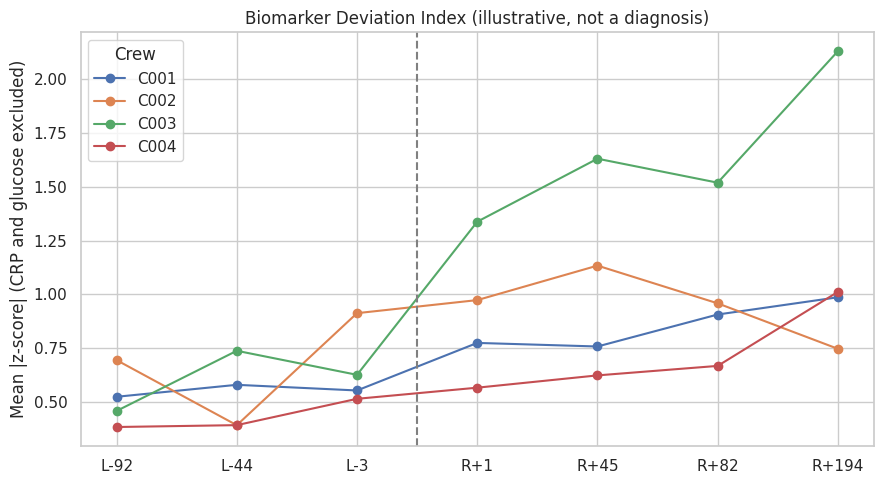

In [137]:
ml_df = ml_df.copy()
index_cols = [c for c in core_cols
              if c not in ("crp_mg_per_L", "glucose_value_milligram_per_deciliter")]
ml_df["Deviation_Index"] = Z[index_cols].abs().mean(axis=1)
print(ml_df.groupby("Timepoint")["Deviation_Index"].mean().reindex(tp_order).round(2))

plt.figure(figsize=(9, 5))
for crew, g in ml_df.groupby("Crew"):
    g = g.sort_values("Day")
    plt.plot(g["Timepoint"], g["Deviation_Index"], marker="o", label=crew)
plt.axvline(2.5, ls="--", color="gray")
plt.ylabel("Mean |z-score| (CRP and glucose excluded)")
plt.title("Biomarker Deviation Index (illustrative, not a diagnosis)")
plt.legend(title="Crew")
plt.tight_layout()
plt.savefig(f"{OUT}/Deviation_Index.png", dpi=200, bbox_inches="tight")
plt.show()

In [138]:
rng_cols = [c for c in ml_df.columns if "_range_" in c and ("hemoglobin" in c or "creatinine" in c)]
print(ml_df.groupby("Crew")[rng_cols].first().T)

Crew                                           C001   C002   C003   C004
hemoglobin_range_min_percent                  13.20  11.70  13.20  13.20
hemoglobin_range_max_percent                  17.10  15.50  17.10  17.10
bun_to_creatinine_ratio_range_min              6.00   6.00   6.00   6.00
bun_to_creatinine_ratio_range_max             22.00  22.00  22.00  22.00
creatinine_range_min_milligram_per_deciliter   0.60   0.50   0.60   0.60
creatinine_range_max_milligram_per_deciliter   1.35   1.05   1.35   1.35


Timepoint
L-92     0.77
L-44     0.79
L-3      0.98
R+1      0.91
R+45     1.04
R+82     1.01
R+194    1.22
Name: Deviation_Index_Fair, dtype: float64


/tmp/ipykernel_439/2357961231.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dev_fair.loc[r] = z.replace([np.inf, -np.inf], np.nan).fillna(0).abs().clip(upper=10).mean()
/tmp/ipykernel_439/2357961231.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dev_fair.loc[r] = z.replace([np.inf, -np.inf], np.nan).fillna(0).abs().clip(upper=10).mean()
/tmp/ipykernel_439/2357961231.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `r

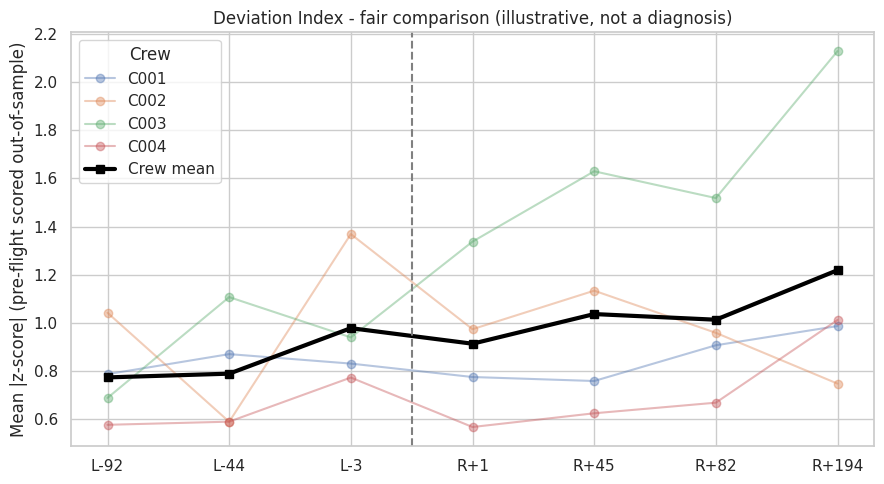


Crew -> reference profile: {'C001': 'Profile A', 'C002': 'Profile B', 'C003': 'Profile C', 'C004': 'Profile A'}

 Profile A
         indicator  value       status
        Hemoglobin   12.5        Watch
        Creatinine    1.2 Within range
C-reactive protein    8.0 No reference

 Profile B
         indicator  value       status
        Hemoglobin   12.5 Within range
        Creatinine    1.2    Attention
C-reactive protein    8.0 No reference

 Profile C
         indicator  value       status
        Hemoglobin   12.5 Within range
        Creatinine    1.2        Watch
C-reactive protein    8.0 No reference


In [139]:
# ===== FAIR DEVIATION INDEX =====
dev_fair = ml_df["Deviation_Index"].copy()
for crew in ml_df["Crew"].unique():
    rows = ml_df.index[(ml_df["Crew"] == crew) & (ml_df["Phase"] == "Pre-flight")]
    for r in rows:
        others = [x for x in rows if x != r]
        mean_o = ml_df.loc[others, index_cols].mean()
        z = (ml_df.loc[r, index_cols] - mean_o) / base_sd.loc[crew, index_cols]
        dev_fair.loc[r] = z.replace([np.inf, -np.inf], np.nan).fillna(0).abs().clip(upper=10).mean()
ml_df["Deviation_Index_Fair"] = dev_fair
print(ml_df.groupby("Timepoint")["Deviation_Index_Fair"].mean().reindex(tp_order).round(2))

plt.figure(figsize=(9, 5))
mean_fair = ml_df.groupby("Timepoint")["Deviation_Index_Fair"].mean().reindex(tp_order)
for crew, g in ml_df.groupby("Crew"):
    g = g.sort_values("Day")
    plt.plot(g["Timepoint"], g["Deviation_Index_Fair"], marker="o", alpha=0.4, label=crew)
plt.plot(tp_order, mean_fair.values, color="black", lw=3, marker="s", label="Crew mean")
plt.axvline(2.5, ls="--", color="gray")
plt.ylabel("Mean |z-score| (pre-flight scored out-of-sample)")
plt.title("Deviation Index - fair comparison (illustrative, not a diagnosis)")
plt.legend(title="Crew")
plt.tight_layout()
plt.savefig(f"{OUT}/Deviation_Index_Fair.png", dpi=200, bbox_inches="tight")
plt.show()

# ===== STEP 7b: TWO LAB-RANGE PROFILES + CRP FIX =====
def ranges_by_crew(col):
    lo_c = col.replace("_value", "_range_min")
    hi_c = col.replace("_value", "_range_max")
    out = {}
    if lo_c == col:          # column has no lab range (e.g. CRP)
        return out
    if lo_c in ml_df.columns and hi_c in ml_df.columns:
        for crew, g in ml_df.groupby("Crew"):
            lo, hi = g[lo_c].median(), g[hi_c].median()
            if pd.notna(lo) and pd.notna(hi):
                out[crew] = (float(lo), float(hi))
    return out

signature = {}
for crew in ml_df["Crew"].unique():
    signature[crew] = tuple(ranges_by_crew(c).get(crew) for c in core_cols)
sig_counts = pd.Series(signature).value_counts()
sig_to_profile = {sig: ("Profile A" if i == 0 else f"Profile {chr(65 + i)}")
                  for i, sig in enumerate(sig_counts.index)}
crew_profile = {crew: sig_to_profile[sig] for crew, sig in signature.items()}
print("\nCrew -> reference profile:", crew_profile)

for col in core_cols:
    rc = ranges_by_crew(col)
    prof_ranges = {}
    for crew, rng_ in rc.items():
        prof_ranges[crew_profile[crew]] = list(rng_)
    reference[col]["ranges"] = prof_ranges
    if prof_ranges:
        reference[col]["lab_min"], reference[col]["lab_max"] = prof_ranges.get("Profile A", list(rc.values())[0])
    else:
        reference[col]["lab_min"], reference[col]["lab_max"] = None, None

with open(f"{OUT}/dashboard_reference.json", "w") as f:
    json.dump(reference, f, indent=2)
with open(f"{OUT}/crew_profiles.json", "w") as f:
    json.dump(crew_profile, f, indent=2)

def evaluate_entry(entry, profile="Profile A"):
    results = []
    for col, info in reference.items():
        if col in entry and entry[col] is not None:
            v = float(entry[col])
            rr = info.get("ranges", {}).get(profile)
            lo, hi = (rr if rr else (None, None))
            status = classify_range(v, lo, hi)
            sd = info["preflight_sd"] if info["preflight_sd"] > 0 else None
            z = (v - info["preflight_mean"]) / sd if sd else None
            if status in ("Within range", "No reference") and z is not None and abs(z) >= 2:
                status = "Watch"
            results.append({"indicator": info["label"], "value": v, "unit": info["unit"],
                            "status": status,
                            "z_vs_sample_baseline": None if z is None else round(z, 2),
                            "tip": RECOMMENDATIONS[info["category"]]})
    for key, r in ILLUSTRATIVE_RULES.items():
        if key in entry and entry[key] is not None:
            v = float(entry[key])
            results.append({"indicator": r["label"], "value": v, "unit": "",
                            "status": classify_rule(v, r), "z_vs_sample_baseline": None,
                            "tip": RECOMMENDATIONS[key]})
    return pd.DataFrame(results)

test = {"hemoglobin_value_percent": 12.5,
        "creatinine_value_milligram_per_deciliter": 1.2,
        "crp_mg_per_L": 8.0}
for p in sorted(set(crew_profile.values())):
    print("\n", p)
    print(evaluate_entry(test, profile=p)[["indicator", "value", "status"]].to_string(index=False))

In [140]:
# ================= FINAL EXPORT CELL (run once, at the very bottom) =================
import json, zipfile, re

# ---- 1) Two lab reference sets (the OSDR files print two different range sets) ----
hb_min = "hemoglobin_range_min_percent"
set1_mask = ml_df[hb_min] == ml_df[hb_min].max()
set2_mask = ml_df[hb_min] == ml_df[hb_min].min()
print("Rows using Reference set 1:", int(set1_mask.sum()), "| Reference set 2:", int(set2_mask.sum()))

def set_range(col, mask):
    lo_c = col.replace("_value", "_range_min")
    hi_c = col.replace("_value", "_range_max")
    if lo_c == col or lo_c not in ml_df.columns or hi_c not in ml_df.columns:
        return None
    lo, hi = ml_df.loc[mask, lo_c].median(), ml_df.loc[mask, hi_c].median()
    return [float(lo), float(hi)] if pd.notna(lo) and pd.notna(hi) else None

for col in core_cols:
    r1_, r2_ = set_range(col, set1_mask), set_range(col, set2_mask)
    ranges = {}
    if r1_: ranges["Reference set 1"] = r1_
    if r2_: ranges["Reference set 2"] = r2_
    reference[col]["ranges"] = ranges
    reference[col]["lab_min"] = r1_[0] if r1_ else None
    reference[col]["lab_max"] = r1_[1] if r1_ else None

with open(f"{OUT}/dashboard_reference.json", "w") as f:
    json.dump(reference, f, indent=2)

# ---- 2) Timeline file (per-crew values + z-scores) ----
long = ml_df[["Crew", "Timepoint", "Day", "Phase"] + core_cols].melt(
    id_vars=["Crew", "Timepoint", "Day", "Phase"], var_name="biomarker", value_name="value")
long["label"] = long["biomarker"].map(lambda c: core[c][0])
zlong = Z[core_cols].assign(Crew=ml_df["Crew"], Timepoint=ml_df["Timepoint"]).melt(
    id_vars=["Crew", "Timepoint"], var_name="biomarker", value_name="z_vs_own_baseline")
long = long.merge(zlong, on=["Crew", "Timepoint", "biomarker"])
long.to_csv(f"{OUT}/dashboard_timeline.csv", index=False)

# ---- 3) Findings file (what the ML/analysis found) ----
def nice_label(c):
    base = re.sub(r"_(concentration|value)_.*$", "", c)
    return base.replace("_", " ").upper()

top_tbl = top.reset_index().rename(columns={"index": "feature"})
top_tbl["label"] = top_tbl["feature"].map(nice_label)
findings = {
    "n_samples": int(len(ml_df)), "n_crew": int(ml_df["Crew"].nunique()),
    "n_features": int(len(feature_cols)),
    "timepoints": tp_order,
    "top_shifted_R1": top_tbl[["label", "mean_pct_change", "mean_z"]].round(2).to_dict("records"),
    "model": {"balanced_accuracy": round(float(obs_bacc), 3), "auc": round(float(obs_auc), 3),
              "permutation_p": round(float(p_value), 3)},
    "deviation_index_fair": ml_df.groupby("Timepoint")["Deviation_Index_Fair"].mean()
                              .reindex(tp_order).round(2).to_dict(),
}
with open(f"{OUT}/findings.json", "w") as f:
    json.dump(findings, f, indent=2)

# ---- 4) Zip the 3 app files and download ----
zpath = "/content/app_assets.zip"
with zipfile.ZipFile(zpath, "w") as z:
    for name in ["dashboard_reference.json", "dashboard_timeline.csv", "findings.json"]:
        z.write(f"{OUT}/{name}", arcname=name)
print("Created", zpath)
print(json.dumps(findings["model"]), findings["deviation_index_fair"])
print(reference["hemoglobin_value_percent"]["ranges"])
print(reference["crp_mg_per_L"]["ranges"])
try:
    from google.colab import files
    files.download(zpath)
except Exception as e:
    print("Download manually:", e)

Rows using Reference set 1: 17 | Reference set 2: 11
Created /content/app_assets.zip
{"balanced_accuracy": 0.833, "auc": 0.958, "permutation_p": 0.025} {'L-92': 0.77, 'L-44': 0.79, 'L-3': 0.98, 'R+1': 0.91, 'R+45': 1.04, 'R+82': 1.01, 'R+194': 1.22}
{'Reference set 1': [13.2, 17.1], 'Reference set 2': [11.7, 15.5]}
{}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>